# Trapping SINDy
## A six-dimensional Lorenz 96 experiment

This notebook follows the Lorenz example in `example.ipynb`, replacing the
three-dimensional Lorenz 1963 system with the six-dimensional Lorenz 96 system.
We identify an energy-preserving quadratic model and examine its predictions,
coefficient accuracy, optimization progress, and trapping region.

A very common issue is that models identified by system identification methods
typically have no guarantees that the models are numerically or physically stable.
Trapping SINDy addresses this by promoting globally bounded models during system
identification. The regression is nonconvex, and the stability result used here
applies to systems with energy-preserving quadratic nonlinearities.

The algorithm is described in Kaptanoglu et al., "Promoting global stability in
data-driven models of quadratic nonlinear dynamics," Physical Review Fluids 6
(2021), 094401. The trapping theorem is developed in Schlegel and Noack,
"On long-term boundedness of Galerkin models," Journal of Fluid Mechanics 765
(2015), 325–352.

Here we use the original, globally constrained algorithm (`method="global"`),
and retain the sampling interval, time horizon, polynomial library, and finite
difference method used in the original Lorenz experiment.

In [1]:
# Import libraries
import warnings

import cvxpy as cp
import numpy as np
import pandas as pd
from scipy.optimize import dual_annealing
from sklearn.exceptions import ConvergenceWarning
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.integrate import solve_ivp

import pysindy as ps
from trapping_utils import (
    integrator_keywords,
    sindy_library,
    make_fits,
    make_lissajou,
    make_progress_plots,
)

%matplotlib inline

# Ignore user warnings, as in the original example.
warnings.filterwarnings("ignore", category=UserWarning)
rng = np.random.default_rng(1)
integrator_keywords = dict(integrator_keywords)

In [2]:
# Utility functions

def lorenz96(t, x, forcing=8.0):
    """Periodic Lorenz 96; the final array axis indexes the state variables."""
    return (
        (np.roll(x, -1, axis=-1) - np.roll(x, 2, axis=-1))
        * np.roll(x, 1, axis=-1)
        - x
        + forcing
    )


def check_stability_lorenz96(C, L, Q, sindy_opt, mean_val):
    """Report stability radii without subtracting nearly equal floating-point roots."""
    m = sindy_opt.m_history_[-1]
    shifted_linear = L + 2 * np.einsum("ijk,k->ij", Q, m)
    As = 0.5 * (shifted_linear + shifted_linear.T)
    eigenvalues = np.linalg.eigvalsh(As)
    d = C + L @ m + np.einsum("ijk,j,k->i", Q, m, m)
    eps_Q = np.linalg.norm(Q + Q.transpose(1, 2, 0) + Q.transpose(2, 0, 1))
    a = -eigenvalues[-1]
    d_norm = np.linalg.norm(d)
    delta = a ** 2 - 4 * eps_Q * d_norm / 3
    if a <= 0 or delta < 0:
        raise ValueError("The fitted model did not satisfy the stability-radius criterion.")
    # Rationalize the small root; this remains accurate as eps_Q approaches zero.
    Rm = 2 * d_norm / (a + np.sqrt(delta))
    R_ls = 3 * (a + np.sqrt(delta)) / (2 * eps_Q) if eps_Q > 0 else np.inf
    print("optimal m:", m)
    print("As eigvals:", eigenvalues)
    print(r"0.5 * |tilde{H}_0|_F =", 0.5 * eps_Q)
    print(r"0.5 * |tilde{H}_0|_F^2 / beta =", 0.5 * eps_Q ** 2 / sindy_opt.beta)
    print("Estimate of trapping region size, Rm =", Rm)
    if mean_val > 0:
        print("Normalized trapping region size, Reff =", Rm / mean_val)
    print("Local stability size, R_ls=", R_ls)
    return Rm, R_ls


def energy_geometry(C, L, Q, m):
    """Full-dimensional Euclidean trapping geometry for an energy-preserving Q."""
    shifted_linear = L + 2 * np.einsum("ijk,k->ij", Q, m)
    As = 0.5 * (shifted_linear + shifted_linear.T)
    eigenvalues, eigenvectors = np.linalg.eigh(As)
    if eigenvalues[-1] >= 0:
        raise ValueError("A^S must be negative definite to construct this geometry.")
    d = C + L @ m + np.einsum("ijk,j,k->i", Q, m, m)
    # Complete the square in y^T A^S y + d^T y, where y = x - m.
    negative_As = -As
    center = 0.5 * np.linalg.solve(negative_As, d)
    level = float(center @ negative_As @ center)
    shape = level * np.linalg.solve(negative_As, np.eye(len(m)))
    return {
        "m": np.array(m, copy=True),
        "As": As,
        "eigenvalues": eigenvalues,
        "eigenvectors": eigenvectors,
        "d": d,
        "center": center,
        "shape": shape,
        "radius": np.linalg.norm(d) / -eigenvalues[-1],
    }


def ellipsoid_surface(center, shape):
    """Mesh of a three-dimensional ellipsoid specified by its shape matrix."""
    eigenvalues, eigenvectors = np.linalg.eigh(shape)
    if np.any(eigenvalues <= 0):
        raise ValueError("The ellipsoid shape must be positive definite.")
    u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 80), np.linspace(0, np.pi, 40))
    sphere = np.array([np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)])
    root = eigenvectors @ np.diag(np.sqrt(eigenvalues))
    return np.einsum("ij,jkl->ikl", root, sphere) + center[:, None, None]


def trapping_region_lorenz96(x_pred, identified, analytic, components=(0, 1, 5)):
    """Project both full-dimensional ellipsoids and the enclosing ball into 3D."""
    if not np.allclose(identified["m"], analytic["m"]):
        raise ValueError("The two geometries must use the same shift.")
    # Rows of projection are eigenvectors: z = V^T (x - m).
    projection = identified["eigenvectors"][:, components].T
    z = (x_pred - identified["m"]) @ projection.T
    fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(9, 9))
    ax.plot(*z.T, "k", linewidth=1.2)

    sphere = ellipsoid_surface(np.zeros(3), identified["radius"] ** 2 * np.eye(3))
    ax.plot_wireframe(*sphere, color="b", rstride=4, cstride=4,
                      linewidth=0.5, alpha=0.35)
    ax.plot_surface(*sphere, color="b", alpha=0.025)
    for geometry, color, width in ((analytic, "g", 1.5), (identified, "r", 0.8)):
        center = projection @ geometry["center"]
        shape = projection @ geometry["shape"] @ projection.T
        surface = ellipsoid_surface(center, shape)
        ax.plot_wireframe(*surface, color=color, rstride=4, cstride=4,
                          linewidth=width, alpha=0.85)

    handles = [
        Line2D([], [], color="k", linewidth=2,
               label="SINDy model prediction with new initial condition"),
        Line2D([], [], color="b", label=r"Trapping region estimate, $B(m,R_m)$"),
        Line2D([], [], color="r", label="Ellipsoid of positive energy growth"),
        Line2D([], [], color="g", label="Lorenz 96 analytic ellipsoid"),
    ]
    ax.legend(handles=handles, loc="upper left", fontsize=11)
    ax.set(xlabel=rf"$z_{components[0]}$", ylabel=rf"$z_{components[1]}$",
           zlabel=rf"$z_{components[2]}$")
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=15, azim=30)
    ax.set_title("Projection of the six-dimensional trapping region", fontsize=15)
    fig.tight_layout()
    return fig


def comparison_operators(fitted_model):
    """Use the same feature ordering and operator projectors for both optimizers."""
    np.testing.assert_array_equal(
        fitted_model.feature_library.powers_, sindy_library.powers_
    )
    coefficients = fitted_model.coefficients().T
    constant = np.tensordot(PC_tensor, coefficients, axes=([2, 1], [0, 1]))
    linear = np.tensordot(PL_tensor, coefficients, axes=([3, 2], [0, 1]))
    quadratic = np.tensordot(PQ_tensor, coefficients, axes=([4, 3], [0, 1]))
    probe = x_test[::100]
    np.testing.assert_allclose(
        constant + probe @ linear.T + np.einsum("ijk,tj,tk->ti", quadratic, probe, probe),
        fitted_model.predict(probe), rtol=1e-12, atol=1e-12,
    )
    return coefficients, constant, linear, quadratic


def comparison_As(shift, linear, quadratic):
    """General shifted symmetric matrix, including non-energy-preserving models."""
    shifted_linear = linear + 2 * np.einsum("ijk,k->ij", quadratic, shift)
    return 0.5 * (shifted_linear + shifted_linear.T)


def anneal_baseline_shift(linear, quadratic):
    """Search for a baseline shift using the actual symmetric shifted Jacobian."""
    def objective(shift):
        return np.linalg.eigvalsh(comparison_As(shift, linear, quadratic))[-1]

    result = dual_annealing(
        objective, bounds=[(-1000.0, 1000.0)] * r,
        x0=np.zeros(r), maxiter=500, seed=123,
    )
    candidates = [np.zeros(r), result.x]
    best_shift = min(candidates, key=objective).copy()
    return best_shift, result


def comparison_stability(constant, linear, quadratic, shift):
    """Return a certified radius, or NaN when the criterion is not satisfied."""
    As = comparison_As(shift, linear, quadratic)
    max_eig = float(np.linalg.eigvalsh(As)[-1])
    cyclic = quadratic + quadratic.transpose(1, 2, 0) + quadratic.transpose(2, 0, 1)
    eps_Q = float(np.linalg.norm(cyclic))
    d = constant + linear @ shift + np.einsum("ijk,j,k->i", quadratic, shift, shift)
    d_norm = float(np.linalg.norm(d))
    radius, outer_radius, certificate = np.nan, np.nan, "Not certified"
    if max_eig < 0:
        a = -max_eig
        if np.max(np.abs(cyclic)) < 1e-10:
            radius, outer_radius, certificate = d_norm / a, np.inf, "Global"
        else:
            delta = a ** 2 - 4 * eps_Q * d_norm / 3
            if delta > 0:
                radius = 2 * d_norm / (a + np.sqrt(delta))
                outer_radius = 3 * (a + np.sqrt(delta)) / (2 * eps_Q)
                certificate = "Local"
    return {
        "max_eigenvalue": max_eig,
        "radius": radius,
        "outer_radius": outer_radius,
        "certificate": certificate,
        "energy_residual": eps_Q,
        "m": shift.copy(),
    }


def lorenz96_tangent(x, tangent):
    """Analytic Jacobian-vector product for the same periodic Lorenz 96 RHS."""
    return (
        (np.roll(x, -1) - np.roll(x, 2)) * np.roll(tangent, 1)
        + (np.roll(tangent, -1) - np.roll(tangent, 2)) * np.roll(x, 1)
        - tangent
    )


def estimate_lorenz96_lyapunov(initial_state, forcing):
    """Largest exponent from periodically renormalized continuous-time tangents."""
    solver_options = dict(method="DOP853", rtol=1e-10, atol=1e-12)
    burn = solve_ivp(lorenz96, (0, 100), initial_state, args=(forcing,), **solver_options)
    assert burn.success
    state = burn.y[:, -1]
    tangent = np.random.default_rng(2028).normal(size=r)
    tangent /= np.linalg.norm(tangent)
    interval = 0.1
    n_align = int(round(20 / interval))
    n_average = int(round(500 / interval))
    log_growth = []

    def variational_rhs(time, augmented):
        x, v = augmented[:r], augmented[r:]
        return np.concatenate((lorenz96(time, x, forcing), lorenz96_tangent(x, v)))

    for step in range(n_align + n_average):
        solution = solve_ivp(
            variational_rhs, (0, interval), np.concatenate((state, tangent)),
            **solver_options,
        )
        assert solution.success
        state = solution.y[:r, -1]
        tangent = solution.y[r:, -1]
        magnitude = np.linalg.norm(tangent)
        assert np.isfinite(magnitude) and magnitude > 0
        tangent /= magnitude
        if step >= n_align:
            log_growth.append(np.log(magnitude))
    log_growth = np.asarray(log_growth)
    exponent = float(np.mean(log_growth) / interval)
    half_estimates = np.mean(np.array_split(log_growth, 2), axis=1) / interval
    return exponent, half_estimates


def identified_rhs(time, state, constant, linear, quadratic):
    """Autonomous polynomial vector field extracted from a fitted SINDy model."""
    return constant + linear @ state + np.einsum("ijk,j,k->i", quadratic, state, state)


def plot_noise_comparison(comparison_table, trapping_label="Trapping SINDy",
                          title="Lorenz 96 identification: clean and noisy observations"):
    """Compare the four identification metrics across the three noise conditions."""
    conditions = ["Clean", "1%", "5%"]
    styles = ((trapping_label, "k--", "o"), ("Naive SINDy (STLSQ)", "b-.", "s"))
    radius_certificates = set(comparison_table["Certificate"])
    radius_ylabel = (
        r"$\rho_+$" if radius_certificates == {"Local"}
        else r"$R_m$" if radius_certificates == {"Global"}
        else "Radius (see legend)"
    )
    metrics = (
        ("Coefficient error", "Coefficient accuracy", "Relative coefficient error (%)", 100.0, False),
        ("Derivative error", "Derivative accuracy", "Time-averaged derivative\nrelative squared error", 1.0, True),
        ("Max eigenvalue", "Stability eigenvalue", r"$\lambda_{\max}(A^S)$", 1.0, False),
        ("Stability radius", "Certified stability radius", radius_ylabel, 1.0, True),
    )
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    x = np.arange(len(conditions))
    for ax, (column, panel_title, ylabel, scale, log_scale) in zip(axes.flat, metrics):
        for model_index, (model_name, style, marker) in enumerate(styles):
            rows = comparison_table[comparison_table["Model"] == model_name].set_index("Data").loc[conditions]
            values = rows[column].to_numpy(dtype=float) * scale
            ax.plot(x, values, style, marker=marker, markersize=6, linewidth=2, label=model_name)
            for position, value in zip(x, values):
                if np.isfinite(value):
                    offset = 9 if model_index == 0 or column == "Coefficient error" else -15
                    if column == "Stability radius":
                        offset = -15 if model_index == 0 else 9
                    label = f"{value:.3g}"
                    if column == "Derivative error":
                        label = f"{value:.2e}"
                    ax.annotate(
                        label, (position, value),
                        xytext=(0, offset),
                        textcoords="offset points", ha="center", fontsize=10,
                        color=style[0],
                    )
                else:
                    ax.text(position, 0.5, "N/A", transform=ax.get_xaxis_transform(),
                            color=style[0], ha="center")
        if log_scale:
            ax.set_yscale("log")
        if column == "Stability radius":
            radius_handles = []
            for model_name, style, marker in styles:
                certificates = comparison_table.loc[
                    comparison_table["Model"] == model_name, "Certificate"
                ].unique()
                symbols = [r"$\rho_+$" if c == "Local" else r"$R_m$" if c == "Global"
                           else "N/A" for c in certificates]
                radius_handles.append(Line2D(
                    [], [], color=style[0], linestyle="--" if style == "k--" else "-.",
                    marker=marker, label=f"{model_name}: {', '.join(symbols)}",
                ))
            ax.legend(handles=radius_handles, loc="best", fontsize=9)
        ax.margins(y=0.30)
        if column == "Coefficient error":
            ax.set_ylim(bottom=0)
        ax.set_title(panel_title, fontsize=15)
        ax.set_ylabel(ylabel, fontsize=12)
        ax.set_xticks(x, conditions)
        ax.set_xlim(-0.2, 2.2)
        ax.grid(True, alpha=0.3)
        ax.tick_params(labelsize=11)
    for ax in axes[-1]:
        ax.set_xlabel("Training observation noise", fontsize=12)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.955),
               ncol=2, fontsize=13)
    certificate_notes = []
    for model_name, _, _ in styles:
        certificates = comparison_table.loc[comparison_table["Model"] == model_name, "Certificate"].unique()
        descriptions = [
            r"Local ($\rho_+$)" if c == "Local" else r"Global ($R_m$)" if c == "Global" else c
            for c in certificates
        ]
        certificate_notes.append(f"{model_name}: {', '.join(descriptions)}")
    fig.text(0.5, 0.015, "Radius certificates — " + "; ".join(certificate_notes),
             ha="center", fontsize=11)
    fig.suptitle(title, fontsize=18)
    fig.tight_layout(rect=(0, 0.045, 1, 0.90))
    return fig


def local_stability_diagnostics(constant, linear, quadratic, shift):
    """Evaluate the residual-aware local radius without assuming a hard energy constraint."""
    As = comparison_As(shift, linear, quadratic)
    eigenvalues, eigenvectors = np.linalg.eigh(As)
    cyclic = quadratic + quadratic.transpose(1, 2, 0) + quadratic.transpose(2, 0, 1)
    eps_Q = float(np.linalg.norm(cyclic))
    d = constant + linear @ shift + np.einsum("ijk,j,k->i", quadratic, shift, shift)
    d_norm = float(np.linalg.norm(d))
    a = -float(eigenvalues[-1])
    delta = a ** 2 - 4 * eps_Q * d_norm / 3
    radius, outer_radius, certificate = np.nan, np.nan, "Not certified"
    if a > 0 and delta > 0:
        radius = 2 * d_norm / (a + np.sqrt(delta))
        outer_radius = 3 * (a + np.sqrt(delta)) / (2 * eps_Q) if eps_Q > 0 else np.inf
        certificate = "Local"
    return {
        "max_eigenvalue": float(eigenvalues[-1]), "eigenvalues": eigenvalues,
        "eigenvectors": eigenvectors, "As": As, "d": d,
        "radius": radius, "outer_radius": outer_radius,
        "certificate": certificate, "energy_residual": eps_Q,
        "m": shift.copy(), "C": constant, "L": linear, "Q": quadratic,
    }


def simulate_polynomial_trajectory(diagnostics, initial_state, times):
    """Integrate the verified polynomial vector field with the original tolerances."""
    solution = solve_ivp(
        identified_rhs, (times[0], times[-1]), initial_state, t_eval=times,
        args=tuple(diagnostics[name] for name in ("C", "L", "Q")),
        **integrator_keywords,
    )
    if not solution.success or len(solution.t) != len(times):
        raise RuntimeError(solution.message)
    trajectory = solution.y.T
    assert np.isfinite(trajectory).all()
    return trajectory


def plot_optimizer_progress(optimizer):
    """Reuse the original progress figures with the actual saved increments."""
    make_progress_plots(r, optimizer)
    figure_numbers = plt.get_fignums()[-2:]
    ax = plt.figure(figure_numbers[0]).axes[0]
    W = np.asarray(optimizer.history_)
    M = np.asarray(optimizer.m_history_)
    ax.lines[0].set_data(np.arange(2, len(W) + 1), np.sum(np.diff(W, axis=0) ** 2, axis=(1, 2)))
    ax.lines[1].set_data(np.arange(1, len(M)), np.sum(np.diff(M, axis=0) ** 2, axis=1))
    if len(W) < 3:
        ax.lines[0].set_marker("o")
    if len(M) < 4:
        ax.lines[1].set_marker("o")
    ax.relim()
    ax.autoscale_view()
    for number in figure_numbers:
        figure = plt.figure(number)
        figure.set_size_inches(8, 5)
        figure.tight_layout()


def plot_local_trapping_region(times, trajectory, diagnostics, analytic):
    """Show the local inner ball in projection and both radii in full-state distance."""
    components = (0, 1, r - 1)
    projection = diagnostics["eigenvectors"][:, components].T
    z = (trajectory - diagnostics["m"]) @ projection.T
    fig = plt.figure(figsize=(16, 7))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot(*z.T, "k", linewidth=1.2)
    inner = ellipsoid_surface(np.zeros(3), diagnostics["radius"] ** 2 * np.eye(3))
    ax.plot_wireframe(*inner, color="b", rstride=4, cstride=4, linewidth=0.5, alpha=0.35)
    reference = ellipsoid_surface(
        projection @ analytic["center"], projection @ analytic["shape"] @ projection.T
    )
    ax.plot_wireframe(*reference, color="g", rstride=4, cstride=4, linewidth=1.0, alpha=0.8)
    ax.legend(handles=[
        Line2D([], [], color="k", label="Local model prediction"),
        Line2D([], [], color="b", label=r"Inner trapping ball, $\rho_-$"),
        Line2D([], [], color="g", label="Lorenz 96 analytic reference ellipsoid"),
    ], loc="upper left", fontsize=10)
    ax.set(xlabel=rf"$z_{components[0]}$", ylabel=rf"$z_{components[1]}$",
           zlabel=rf"$z_{components[2]}$")
    ax.set_title("Projection of the local inner trapping ball", fontsize=14)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=15, azim=30)

    bounds = fig.add_subplot(1, 2, 2)
    distances = np.linalg.norm(trajectory - diagnostics["m"], axis=1)
    bounds.semilogy(times, distances, "k", label=r"$\|\mathbf{x}(t)-\mathbf{m}\|_2$")
    bounds.axhline(diagnostics["radius"], color="b", label=r"Inner radius $\rho_-$")
    if np.isfinite(diagnostics["outer_radius"]):
        bounds.axhline(diagnostics["outer_radius"], color="tab:orange", linestyle="--",
                       label=r"Outer stability radius $\rho_+$")
    bounds.set(xlabel="t", ylabel="Full six-dimensional distance",
               title="Local inner and outer radii")
    bounds.grid(True, alpha=0.3)
    bounds.legend(fontsize=11)
    fig.tight_layout()
    return fig


class QRTrappingSR3(ps.TrappingSR3):
    """Native local objectives with equivalent QR compression and a CVXPY backend."""

    def _update_coef_cvxpy(self, xi, cost, var_len, coef_prev, tol):
        # Inherited methods construct the local loss and built-in L1/L2 penalty.
        # Only the CVXPY backend is chosen explicitly for this ill-conditioned QP.
        if self.method != "local" or self.use_constraints:
            raise ValueError("This numerical adapter is only used for unconstrained local fits.")
        problem = cp.Problem(cp.Minimize(cost))
        problem.solve(
            solver=cp.CLARABEL, max_iter=self.max_iter,
            tol_gap_abs=tol, tol_gap_rel=tol, tol_feas=tol,
        )
        self.solver_statuses_.append(problem.status)
        if problem.status != cp.OPTIMAL or xi.value is None:
            warnings.warn(f"Solver failed to reach optimal status: {problem.status}", ConvergenceWarning)
        if xi.value is None:
            return None
        return np.asarray(xi.value).reshape(coef_prev.shape)

    def fit(self, x_, y, sample_weight=None, **reduce_kws):
        if sample_weight is not None:
            raise ValueError("The current experiments do not use sample weights.")
        design, targets = np.asarray(x_), np.asarray(y)
        valid = np.isfinite(design).all(axis=1) & np.isfinite(targets).all(axis=1)
        design, targets = design[valid], targets[valid]
        q, triangular = np.linalg.qr(design, mode="reduced")
        projected = q.T @ targets
        np.testing.assert_allclose(
            triangular.T @ triangular, design.T @ design, rtol=1e-10, atol=1e-7
        )
        np.testing.assert_allclose(
            triangular.T @ projected, design.T @ targets, rtol=1e-9, atol=1e-7
        )
        self.regression_samples_ = len(design)
        self.compressed_samples_ = len(triangular)
        self.solver_statuses_ = []
        return super().fit(triangular, projected, **reduce_kws)


def fit_regularized_local(observations, times, regularizer, strength, screening=False, weighting="std"):
    """Fit the native local method; strength is the penalty weight per sample."""
    library = ps.PolynomialLibrary(include_bias=True)
    features = library.fit_transform(observations)
    native_weight = strength * (len(times) - 2)
    if regularizer.startswith("weighted"):
        scales = np.ones(features.shape[1]) if weighting == "uniform" else np.std(features, axis=0, ddof=0)
        if regularizer.endswith("l2"):
            scales = scales ** 2
        # A free intercept is standard in scale-weighted regression. It is fitted,
        # rather than fixed to the known Lorenz 96 forcing.
        scales[np.sum(library.powers_, axis=1) == 0] = 0
        native_weight = np.broadcast_to(native_weight * scales, (r, features.shape[1])).copy()
    optimizer_class = ps.TrappingSR3 if strength == 0 else QRTrappingSR3
    optimizer = optimizer_class(
        method="local", _n_tgts=r, _include_bias=True,
        regularizer=regularizer, reg_weight_lam=native_weight,
        eta=eta, alpha_m=alpha_m, max_iter=max_iter, gamma=-1,
        m0=np.zeros(r), alpha=local_alpha, beta=local_beta,
        eps_solver=1e-7, verbose=False,
        tol=1e-4 if screening else 1e-5,
        tol_m=1e-3 if screening else 1e-5,
    )
    assert not optimizer.use_constraints
    fitted = ps.SINDy(
        optimizer=optimizer, feature_library=library,
        differentiation_method=ps.FiniteDifference(drop_endpoints=True),
    )
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        fitted.fit(observations, t=times)
    messages = sorted({str(w.message) for w in captured if not issubclass(w.category, (FutureWarning, DeprecationWarning, PendingDeprecationWarning))})
    return fitted, messages


def fitted_local_diagnostics(fitted):
    """Extract physical operators without consulting the independent test set."""
    optimizer = fitted.optimizer
    coefficients = fitted.coefficients().T
    constant = np.tensordot(optimizer.PC_, coefficients, axes=([2, 1], [0, 1]))
    linear = np.tensordot(optimizer.PL_unsym_, coefficients, axes=([3, 2], [0, 1]))
    quadratic = np.tensordot(optimizer.PQ_, coefficients, axes=([4, 3], [0, 1]))
    return local_stability_diagnostics(constant, linear, quadratic, optimizer.m_history_[-1])


def regularization_validation_loss(fitted, observations, times):
    """Aggregate normalized derivative MSE on a training-only validation block."""
    reference = ps.FiniteDifference(drop_endpoints=True)._differentiate(observations, times)
    valid = np.isfinite(reference).all(axis=1)
    residual = reference[valid] - fitted.predict(observations)[valid]
    return float(np.sum(residual ** 2) / np.sum(reference[valid] ** 2))


def search_local_regularization(observations, times, clean, zero_tolerance):
    """Select a penalty using an 80/20 chronological split and a two-sample gap."""
    split = int(0.8 * len(times))
    fitting_x, fitting_t = observations[:split], times[:split]
    validation_x, validation_t = observations[split + 2:], times[split + 2:]
    grids = {
        "l1": (0.003, 0.03, 0.3, 3.0),
        "l2": (0.0001, 0.001, 0.01),
        "weighted_l1": (0.003, 0.01, 0.03, 0.06, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0),
        "weighted_l2": (0.00001, 0.0001, 0.001, 0.01),
    }
    settings = [("l1", 0.0, "none")] + [(name, value, "std" if name.startswith("weighted") else "none") for name, values in grids.items() for value in values]
    settings += [("weighted_l1", value, "uniform") for value in (0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0)]
    settings += [("weighted_l2", value, "uniform") for value in (0.0001, 0.001, 0.01)]
    rows = []
    for name, strength, weighting in settings:
        penalty_label = f"{name} ({weighting})" if name.startswith("weighted") else name
        try:
            fitted, messages = fit_regularized_local(fitting_x, fitting_t, name, strength, screening=True, weighting=weighting)
            diagnostic = fitted_local_diagnostics(fitted)
            loss = regularization_validation_loss(fitted, validation_x, validation_t)
            terms = int(np.count_nonzero(np.abs(fitted.coefficients()) > zero_tolerance))
            inaccurate = any(
                "inaccurate" in message.lower() or "solver failed" in message.lower()
                or "infeasible" in message.lower() or "did not converge" in message.lower()
                for message in messages
            )
            valid = diagnostic["certificate"] == "Local" and np.isfinite(loss) and not inaccurate
            if valid:
                distances = np.linalg.norm(validation_x - diagnostic["m"], axis=1)
                valid = bool(np.all(distances < diagnostic["outer_radius"]))
            rows.append({
                "Regularizer": name, "Weighting": weighting, "Penalty": penalty_label,
                "Strength": strength, "Validation loss": loss,
                "Effective terms": terms, "Valid": valid,
                "Max eigenvalue": diagnostic["max_eigenvalue"],
                "Inner radius": diagnostic["radius"], "Outer radius": diagnostic["outer_radius"],
                "Iterations": len(fitted.optimizer.history_), "Warnings": "; ".join(messages),
            })
        except (ValueError, RuntimeError, np.linalg.LinAlgError, cp.error.SolverError) as error:
            rows.append({
                "Regularizer": name, "Weighting": weighting, "Penalty": penalty_label,
                "Strength": strength, "Validation loss": np.inf,
                "Effective terms": r * features_count_for_local(), "Valid": False,
                "Max eigenvalue": np.nan, "Inner radius": np.nan, "Outer radius": np.nan,
                "Iterations": 0, "Warnings": str(error),
            })
    results = pd.DataFrame(rows)
    candidates = results[results["Valid"] & (results["Strength"] > 0)].copy()
    if candidates.empty:
        raise RuntimeError("No converged regularized local candidate has a valid local radius.")
    if clean:
        # A 2% validation derivative NRMSE ceiling allows a small accuracy tradeoff
        # while prioritizing clean-data sparsity. No analytic support is used.
        reference_loss = float(results.iloc[0]["Validation loss"])
        ceiling = max(0.02 ** 2, 1.25 * reference_loss)
        admissible = candidates[candidates["Validation loss"] <= ceiling]
        if admissible.empty:
            admissible = candidates.nsmallest(1, "Validation loss")
        ranked = admissible.sort_values(["Effective terms", "Validation loss", "Strength"])
    else:
        # Accuracy first; sparsity only breaks numerical ties in validation loss.
        minimum = float(candidates["Validation loss"].min())
        admissible = candidates[candidates["Validation loss"] <= minimum + 1e-8 * max(1.0, minimum)]
        ranked = admissible.sort_values(["Effective terms", "Validation loss", "Strength"])
    selected = None
    for _, specification in ranked.iterrows():
        fitted, messages = fit_regularized_local(
            observations, times, specification["Regularizer"], float(specification["Strength"]),
            weighting=specification["Weighting"],
        )
        diagnostic = fitted_local_diagnostics(fitted)
        inaccurate = any(
            "inaccurate" in message.lower() or "solver failed" in message.lower()
            or "infeasible" in message.lower() or "did not converge" in message.lower()
            for message in messages
        )
        if diagnostic["certificate"] == "Local" and not inaccurate:
            selected = specification.to_dict()
            selected.update({
                "Final effective terms": int(np.count_nonzero(np.abs(fitted.coefficients()) > zero_tolerance)),
                "Final iterations": len(fitted.optimizer.history_), "Final warnings": "; ".join(messages),
            })
            break
    if selected is None:
        raise RuntimeError("No shortlisted penalty retained a converged local certificate after refitting.")
    return fitted, diagnostic, results, selected


def features_count_for_local():
    return (r + 1) * (r + 2) // 2


def plot_local_regularization_search(paths, selections, sparsity_summary, zero_tolerance):
    """Show the training-only validation paths and the resulting sparsity counts."""
    styles = {
        "l1": ("k", "o"), "l2": ("0.55", "s"),
        "weighted_l1 (std)": ("tab:blue", "^"), "weighted_l2 (std)": ("tab:orange", "D"),
        "weighted_l1 (uniform)": ("tab:purple", "v"), "weighted_l2 (uniform)": ("tab:cyan", "P"),
    }
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, label in zip(axes.flat, ("Clean", "1%", "5%")):
        path = paths[label]
        for name, (color, marker) in styles.items():
            rows = path[(path["Penalty"] == name) & (path["Strength"] > 0)].sort_values("Strength")
            rows = rows[rows["Valid"] & np.isfinite(rows["Validation loss"])]
            ax.loglog(rows["Strength"], rows["Validation loss"], color=color, marker=marker,
                      linewidth=1.2, markersize=4, label=name)
        reference = float(path.iloc[0]["Validation loss"])
        ax.axhline(reference, color="tab:green", linestyle=":", linewidth=1.5, label="unregularized local")
        selected = selections[label]
        ax.scatter(selected["Strength"], selected["Validation loss"], marker="*", s=160,
                   color="red", zorder=5, label="Selected regularization configuration")
        ax.set_title(
            f"{label}: {selected['Penalty']}, lambda={selected['Strength']:g}", fontsize=12
        )
        ax.set_xlabel("Penalty strength per fitting sample", fontsize=11)
        ax.set_ylabel("Training-validation derivative loss", fontsize=11)
        if label != "Clean":
            ax.set_yscale("linear")
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)
            ax.locator_params(axis="y", nbins=5)
        ax.grid(True, alpha=0.3)
    ax = axes[1, 1]
    x = np.arange(3)
    width = 0.24
    for offset, column, color, label in (
        (-width, "Unregularized terms", "0.7", "Unregularized local"),
        (0, "Selected terms", "k", "Selected local"),
        (width, "Baseline terms", "b", "Naive SINDy (STLSQ)"),
    ):
        values = sparsity_summary[column].to_numpy(dtype=int)
        bars = ax.bar(x + offset, values, width, color=color, label=label)
        ax.bar_label(bars, fontsize=10, padding=3)
    ax.set_xticks(x, ("Clean", "1%", "5%"))
    ax.set_ylabel("Effective nonzero coefficients", fontsize=11)
    ax.set_title("Full-data refits: sparsity comparison", fontsize=13)
    ax.set_ylim(0, 1.45 * max(sparsity_summary["Unregularized terms"].max(), sparsity_summary["Selected terms"].max()))
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend(loc="upper right", ncol=3, fontsize=8)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=4, fontsize=9)
    fig.suptitle("Local regularization: training-only selection and sparsity", fontsize=17)
    fig.text(0.5, 0.015,
             rf"Red stars: selected penalties. Effective terms use $|\xi|>{zero_tolerance:g}$; coefficients are not pruned.",
             ha="center", fontsize=11)
    fig.tight_layout(rect=(0, 0.045, 1, 0.86))
    return fig


def plot_local_support_comparison(local_fitted, baseline_fitted, analytic_coefficients,
                                  feature_names, zero_tolerance, noise_label):
    """Compare analytic, local, and STLSQ supports using fixed 2-by-2 subcells."""
    analytic = np.abs(analytic_coefficients.T) > zero_tolerance
    local = np.abs(local_fitted.coefficients()) > zero_tolerance
    baseline = np.abs(baseline_fitted.coefficients()) > zero_tolerance
    assert analytic.shape == local.shape == baseline.shape
    n_states, n_features = analytic.shape
    # Within each coefficient: analytic / local on top, STLSQ / unused below.
    tiles = np.zeros((2 * n_states, 2 * n_features), dtype=int)
    tiles[0::2, 0::2] = analytic.astype(int)
    tiles[0::2, 1::2] = 2 * local.astype(int)
    tiles[1::2, 0::2] = 3 * baseline.astype(int)
    fig, ax = plt.subplots(figsize=(17, 5))
    ax.imshow(
        tiles, cmap=ListedColormap(("white", "tab:green", "black", "blue")),
        vmin=0, vmax=3, aspect="auto", interpolation="nearest",
        extent=(-0.5, n_features - 0.5, n_states - 0.5, -0.5),
    )
    ax.vlines(np.arange(-0.5, n_features, 0.5), -0.5, n_states - 0.5,
              color="0.85", linewidth=0.4)
    ax.hlines(np.arange(-0.5, n_states, 0.5), -0.5, n_features - 0.5,
              color="0.85", linewidth=0.4)
    ax.vlines(np.arange(-0.5, n_features, 1), -0.5, n_states - 0.5,
              color="0.55", linewidth=0.7)
    ax.hlines(np.arange(-0.5, n_states, 1), -0.5, n_features - 0.5,
              color="0.55", linewidth=0.7)
    ax.set_xticks(np.arange(n_features), feature_names, rotation=90, fontsize=10)
    ax.set_yticks(np.arange(n_states), [rf"$\dot x_{{{i}}}$" for i in range(n_states)], fontsize=12)
    ax.set_title(
        f"{noise_label} support: analytic {np.count_nonzero(analytic)}, "
        f"local {np.count_nonzero(local)}, naive {np.count_nonzero(baseline)} effective terms",
        fontsize=15,
    )
    fig.legend(handles=[
        Patch(facecolor="tab:green", label="Analytic (top left)"),
        Patch(facecolor="black", label="Local SINDy (top right)"),
        Patch(facecolor="blue", label="Naive SINDy / STLSQ (bottom left)"),
    ], loc="lower center", bbox_to_anchor=(0.5, 0.055), ncol=3, fontsize=11)
    fig.text(
        0.5, 0.015,
        rf"Each coefficient uses a 2 x 2 tile; bottom right is unused. White: absent or unused. "
        rf"Effective terms: $|\xi|>{zero_tolerance:g}$.",
        ha="center", fontsize=11,
    )
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    return fig


## The trapping algorithm requires energy-preserving quadratic nonlinear structure

As in the original example, we explicitly constrain the coefficients to conform
to this structure. `TrappingSR3(method="global")` constructs the quadratic
energy-preserving equality constraints, and `sindy_library` contains the constant,
linear, and quadratic terms. The constant term is retained because Lorenz 96 has
external forcing.

# Lorenz 96 model

The Lorenz 96 system is a simplified model of atmospheric dynamics introduced by
Lorenz in "Predictability—a problem partly solved" (1996). Its variables form a
periodic chain, with quadratic advection, linear dissipation, and constant forcing:

$$
\dot{x}_i=(x_{i+1}-x_{i-2})x_{i-1}-x_i+F,
\qquad i=0,\ldots,N-1,
\qquad x_{i+N}=x_i.
$$

For this experiment we choose $N=6$ and $F=8$. Writing
$\dot{\mathbf{x}}=\mathbf{C}+\mathbf{L}\mathbf{x}
+\mathbf{Q}(\mathbf{x},\mathbf{x})$, the quadratic terms obey

$$
\mathbf{x}^{T}\mathbf{Q}(\mathbf{x},\mathbf{x})
=\sum_i x_{i-1}x_ix_{i+1}-\sum_i x_{i-2}x_{i-1}x_i=0.
$$

For the analytic model, $\mathbf{C}=F\mathbf{1}$ and $\mathbf{L}=-\mathbf{I}$.
The shift $\mathbf{m}=0$ gives $\mathbf{A}^{S}=-\mathbf{I}$, and a trapping ball
has radius $R_0=|F|\sqrt{N}$. The algorithm below fits the full quadratic model
from data; its coefficients and shift remain free to vary.

Reference: [Lorenz, Predictability—a problem partly solved](https://www.ecmwf.int/sites/default/files/elibrary/1995/75462-predictability-problem-partly-solved_0.pdf).

In [3]:
# Define parameters and make independent training and testing trajectories.
r = N = 6
F = 8.0
dt = 0.01
T = 40
t = np.arange(0, T + dt, dt)
t_span = (t[0], t[-1])

# A small perturbation of the uniform equilibrium includes the initial transient.
x0_train = F * np.ones(r)
x0_train[0] += 0.01
x0_test = (rng.random(r) - 0.5) * 30

train_solution = solve_ivp(
    lorenz96, t_span, x0_train, t_eval=t, args=(F,), **integrator_keywords
)
test_solution = solve_ivp(
    lorenz96, t_span, x0_test, t_eval=t, args=(F,), **integrator_keywords
)
assert train_solution.success and test_solution.success
x_train = train_solution.y.T
x_test = test_solution.y.T
assert x_train.shape == x_test.shape == (len(t), r)

print("Training initial condition:", x0_train)
print("Testing initial condition:", x0_test)
print("Training and testing data shapes:", x_train.shape, x_test.shape)

Training initial condition: [8.01 8.   8.   8.   8.   8.  ]
Testing initial condition: [  0.35464874  13.51391089 -10.67521162  13.45948341  -5.64505644
  -2.30020653]
Training and testing data shapes: (4001, 6) (4001, 6)


# Identifying a stable Lorenz 96 model

We use one training trajectory and a second trajectory with a different initial
condition for testing, as in the Lorenz example. No observation noise is added.
The sparsity weight is zero so that the effects of the energy constraint and
stability promotion can be examined directly.

The shift is initialized at zero, a natural reference for this system. We use a
smaller shift-update step than in the three-dimensional example, and allow up to
5000 iterations. All six variables are retained in the regression and simulation.

In [4]:
# Define hyperparameters.
reg_weight_lam = 0
max_iter = 5000
eta = 1.0e3
alpha_m = 1.0e-1 * eta

# Run trapping SINDy.
sindy_opt = ps.TrappingSR3(
    method="global",
    _n_tgts=r,
    _include_bias=True,
    reg_weight_lam=reg_weight_lam,
    eta=eta,
    alpha_m=alpha_m,
    max_iter=max_iter,
    gamma=-1,
    m0=np.zeros(r),
    verbose=True,
)
model = ps.SINDy(
    optimizer=sindy_opt,
    feature_library=sindy_library,
    differentiation_method=ps.FiniteDifference(drop_endpoints=True),
)
model.fit(x_train, t=t)
model.print()
print("Number of optimizer iterations =", len(sindy_opt.history_))

Xi = model.coefficients().T
xdot_test = model.differentiate(x_test, t=t)
xdot_test_pred = model.predict(x_test)
x_train_pred = model.simulate(x_train[0], t, integrator_kws=integrator_keywords)
x_test_pred = model.simulate(x_test[0], t, integrator_kws=integrator_keywords)
assert np.isfinite(x_train_pred).all() and np.isfinite(x_test_pred).all()

 Iter ... |y-Xw|^2 ... |Pw-A|^2/eta ... |w|_1 ... |Qijk|/a ... |Qijk+...|/b ...   Total:
    0 ... 2.707e+01 ... 1.169e-07 ... 0.00e+00 ... 2.98e-20 ... 1.02e-48 ... 2.71e+01


(x0)' = 7.976 1 + -0.995 x0 + 0.002 x2 + 0.003 x4 + -0.007 x5 + -0.001 x0 x3 + 0.998 x1 x5 + 0.001 x2 x5 + -0.001 x3 x4 + -0.997 x4 x5
(x1)' = 7.974 1 + -0.003 x0 + -0.995 x1 + 0.001 x2 + 0.003 x3 + -0.001 x4 + 0.998 x0 x2 + 0.001 x0 x3 + -0.998 x0 x5 + -0.001 x1 x4 + 0.001 x2 x4 + -0.001 x4 x5
(x2)' = 7.977 1 + 0.002 x0 + -0.004 x1 + -0.996 x2 + 0.001 x3 + 0.002 x4 + -0.002 x5 + -0.998 x0 x1 + -0.001 x0 x5 + 0.998 x1 x3 + 0.001 x1 x5 + -0.001 x2 x5 + 0.001 x5^2
(x3)' = 7.976 1 + -0.001 x0 + -0.006 x2 + -0.997 x3 + -0.002 x5 + 0.001 x0^2 + -0.001 x0 x1 + -0.998 x1 x2 + 0.997 x2 x4 + 0.001 x2 x5 + 0.001 x5^2
(x4)' = 7.949 1 + -0.001 x1 + 0.001 x2 + -0.002 x3 + -0.995 x4 + 0.005 x5 + 0.001 x0 x3 + 0.001 x1^2 + -0.001 x1 x2 + -0.997 x2 x3 + 0.996 x3 x5
(x5)' = 7.966 1 + 0.002 x0 + 0.004 x1 + 0.004 x3 + -0.008 x4 + -0.993 x5 + 0.997 x0 x4 + 0.001 x1 x4 + 0.001 x2^2 + -0.001 x2 x3 + -0.001 x2 x5 + -0.995 x3 x4 + -0.001 x3 x5
Number of optimizer iterations = 91


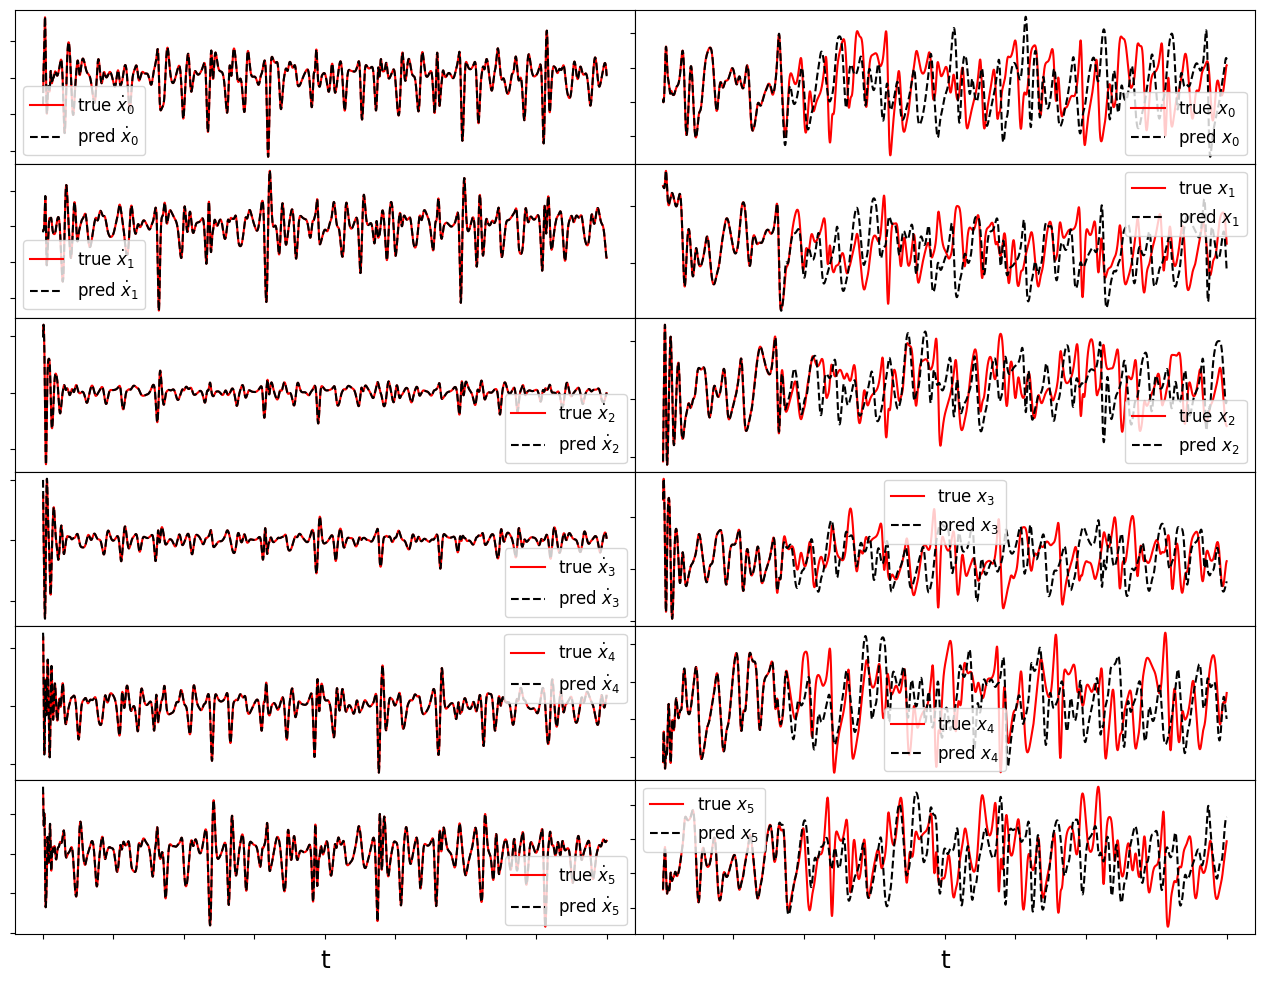

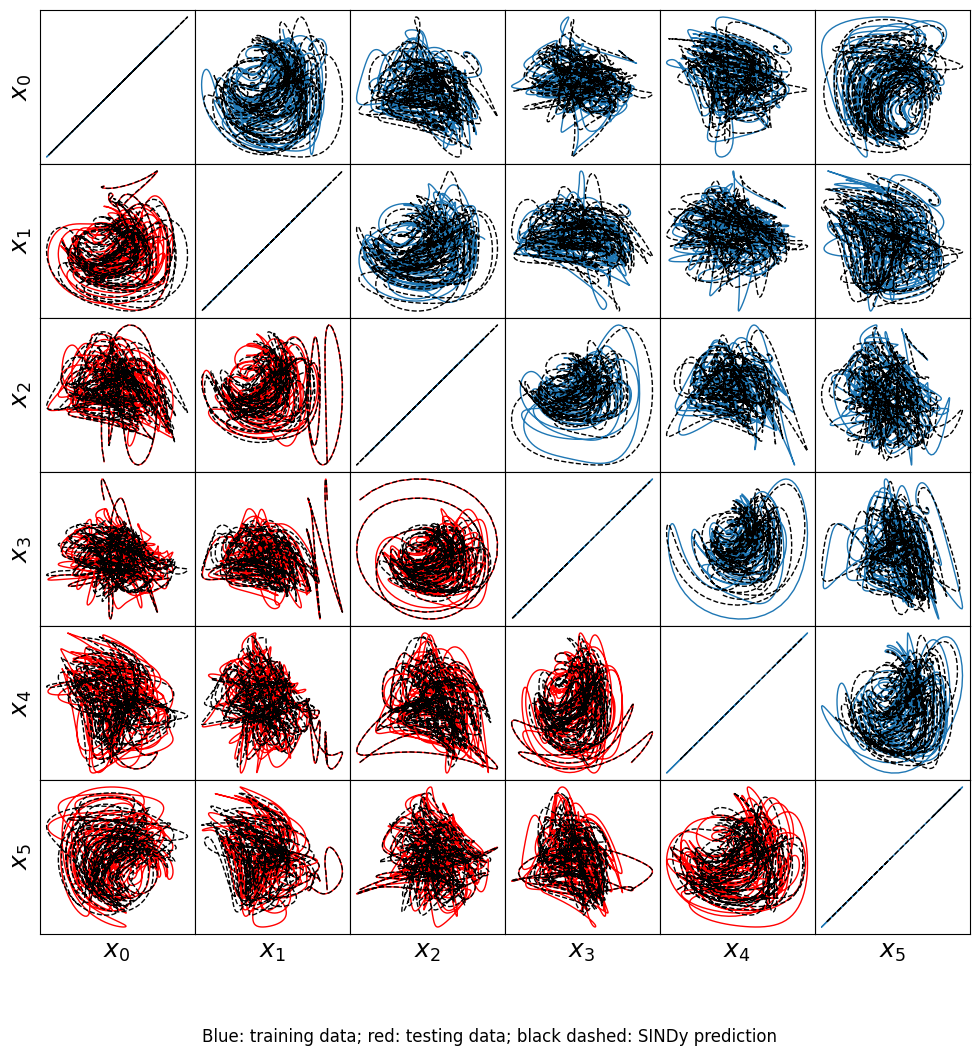

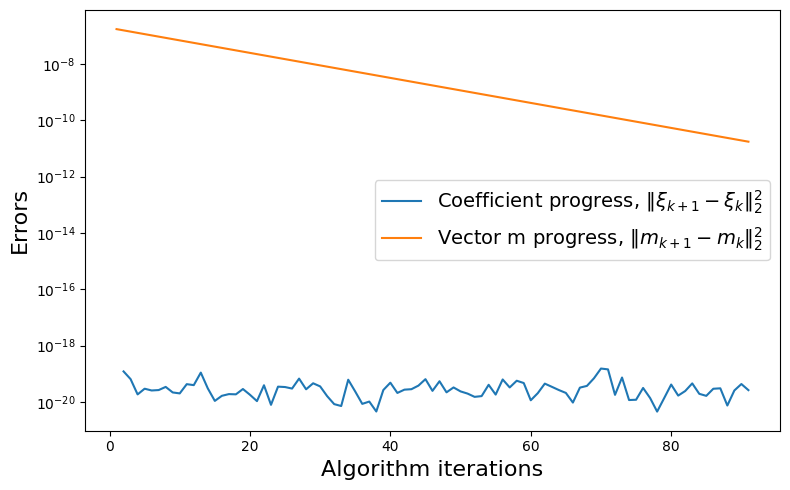

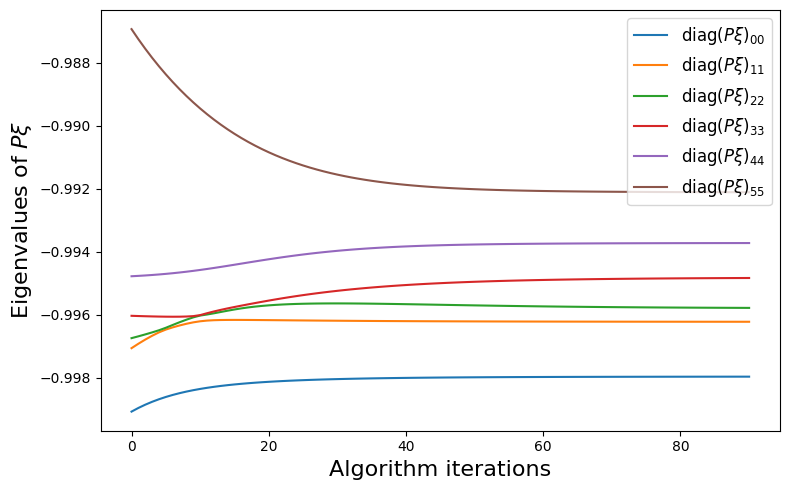

In [5]:
# Plotting and analysis: use the same four diagnostic figures as example.ipynb.
make_fits(r, t, xdot_test, xdot_test_pred, x_test, x_test_pred, "lorenz96")
plt.gcf().set_size_inches(16, 12)
plt.show()

make_lissajou(r, x_train, x_test, x_train_pred, x_test_pred, "lorenz96")
plt.gcf().set_size_inches(12, 12)
plt.gcf().text(
    0.5, 0.02,
    "Blue: training data; red: testing data; black dashed: SINDy prediction",
    ha="center", fontsize=12,
)
plt.show()

make_progress_plots(r, sindy_opt)
# Replace the helper's zero-padded increments with the actual saved differences.
progress_ax = plt.figure(plt.get_fignums()[-2]).axes[0]
W = np.asarray(sindy_opt.history_)
M = np.asarray(sindy_opt.m_history_)
progress_ax.lines[0].set_data(
    np.arange(2, len(W) + 1), np.sum(np.diff(W, axis=0) ** 2, axis=(1, 2))
)
progress_ax.lines[1].set_data(
    np.arange(1, len(M)), np.sum(np.diff(M, axis=0) ** 2, axis=1)
)
progress_ax.relim()
progress_ax.autoscale_view()
for figure_number in plt.get_fignums():
    fig = plt.figure(figure_number)
    fig.set_size_inches(8, 5)
    fig.tight_layout()
plt.show()

In [6]:
# Extract constant, unsymmetrized linear, and symmetric quadratic operators.
PC_tensor = sindy_opt.PC_
PL_tensor = sindy_opt.PL_unsym_
PQ_tensor = sindy_opt.PQ_
C = np.tensordot(PC_tensor, Xi, axes=([2, 1], [0, 1]))
L = np.tensordot(PL_tensor, Xi, axes=([3, 2], [0, 1]))
Q = np.tensordot(PQ_tensor, Xi, axes=([4, 3], [0, 1]))
Q_cyclic = Q + np.transpose(Q, (1, 2, 0)) + np.transpose(Q, (2, 0, 1))
Q_sum = np.max(np.abs(Q_cyclic))
print("Max deviation from the constraints =", Q_sum)

mean_val = np.linalg.norm(np.mean(x_test_pred, axis=0))
Rm, R_ls = check_stability_lorenz96(C, L, Q, sindy_opt, mean_val)

# Compute the relative Frobenius error in the model coefficients.
# Use library powers so that the analytic coefficients match its actual ordering.
terms = sindy_library.get_feature_names()
power_index = {tuple(power): i for i, power in enumerate(sindy_library.powers_)}
Xi_lorenz96 = np.zeros_like(Xi)
for i in range(r):
    Xi_lorenz96[power_index[(0,) * r], i] = F
    power = np.zeros(r, dtype=int)
    power[i] = 1
    Xi_lorenz96[power_index[tuple(power)], i] = -1
    for j, k, value in (
        ((i - 1) % r, (i + 1) % r, 1.0),
        ((i - 1) % r, (i - 2) % r, -1.0),
    ):
        power = np.zeros(r, dtype=int)
        power[j] += 1
        power[k] += 1
        Xi_lorenz96[power_index[tuple(power)], i] += value

C_true = np.tensordot(PC_tensor, Xi_lorenz96, axes=([2, 1], [0, 1]))
L_true = np.tensordot(PL_tensor, Xi_lorenz96, axes=([3, 2], [0, 1]))
Q_true = np.tensordot(PQ_tensor, Xi_lorenz96, axes=([4, 3], [0, 1]))

# Check the analytic coefficient ordering against the independent ODE definition.
np.testing.assert_allclose(
    sindy_library.transform(x_test) @ Xi_lorenz96,
    lorenz96(0, x_test, F), rtol=1e-12, atol=1e-12,
)
np.testing.assert_allclose(
    C + x_test @ L.T + np.einsum("ijk,tj,tk->ti", Q, x_test, x_test),
    xdot_test_pred, rtol=1e-12, atol=1e-12,
)

E_pred = np.linalg.norm(x_test - x_test_pred) / np.linalg.norm(x_test)
coef_pred = np.linalg.norm(Xi_lorenz96 - Xi) / np.linalg.norm(Xi_lorenz96)
deriv_error = np.sum((xdot_test - xdot_test_pred) ** 2, axis=1) / np.sum(
    xdot_test ** 2, axis=1
)
deriv_error_mean = np.nanmean(deriv_error)
print("Frobenius error =", E_pred)
print("Frobenius coefficient error =", coef_pred)
print("Time-averaged derivative error =", deriv_error_mean)

# Also compare against the analytic derivative, independently of finite differences.
xdot_test_exact = lorenz96(0, x_test, F)
exact_deriv_error_mean = np.mean(
    np.sum((xdot_test_exact - xdot_test_pred) ** 2, axis=1)
    / np.sum(xdot_test_exact ** 2, axis=1)
)
print("Time-averaged derivative error (analytic RHS) =", exact_deriv_error_mean)

Max deviation from the constraints = 1.9544438224945726e-15
optimal m: [0.00343265 0.00444338 0.00357112 0.00346193 0.00299197 0.00170726]
As eigvals: [-0.9979613  -0.99622067 -0.99578151 -0.99483176 -0.99372423 -0.99211375]
0.5 * |tilde{H}_0|_F = 5.920688222068384e-15
0.5 * |tilde{H}_0|_F^2 / beta = 7.010909804587856e-49
Estimate of trapping region size, Rm = 19.668613899155435
Normalized trapping region size, Reff = 3.420094692584847
Local stability size, R_ls= 251350951749367.0
Frobenius error = 0.950858327742859
Frobenius coefficient error = 0.004084748539053395
Time-averaged derivative error = 4.231857872956031e-06
Time-averaged derivative error (analytic RHS) = 5.9345628842049925e-06


# Visualizing the trapping region for Lorenz 96

Below, we plot the SINDy-identified ellipsoid of positive energy growth (red),
the analytic Lorenz 96 ellipsoid (green), and the trapping ball estimate (blue).
The black curve is the SINDy model prediction from the independent testing initial
condition. The identified and analytic geometries use the same shift and the same
eigenvector coordinates of the identified $\mathbf{A}^{S}$.

The original plotting helper is specific to the three-dimensional Lorenz 1963
system. Here we calculate the full six-dimensional geometry, including the
constant forcing, and project it onto three eigenvector coordinates. In
particular, the projected analytic ellipsoid is obtained from its full shape
matrix, rather than by dropping three state variables.

Global structural certificate (within numerical tolerance): True
Analytic trapping radius at m = 0 = 19.595917942265423
Identified trapping radius at learned m = 19.6686138991539
Analytic trapping radius at learned m = 19.66800096723447


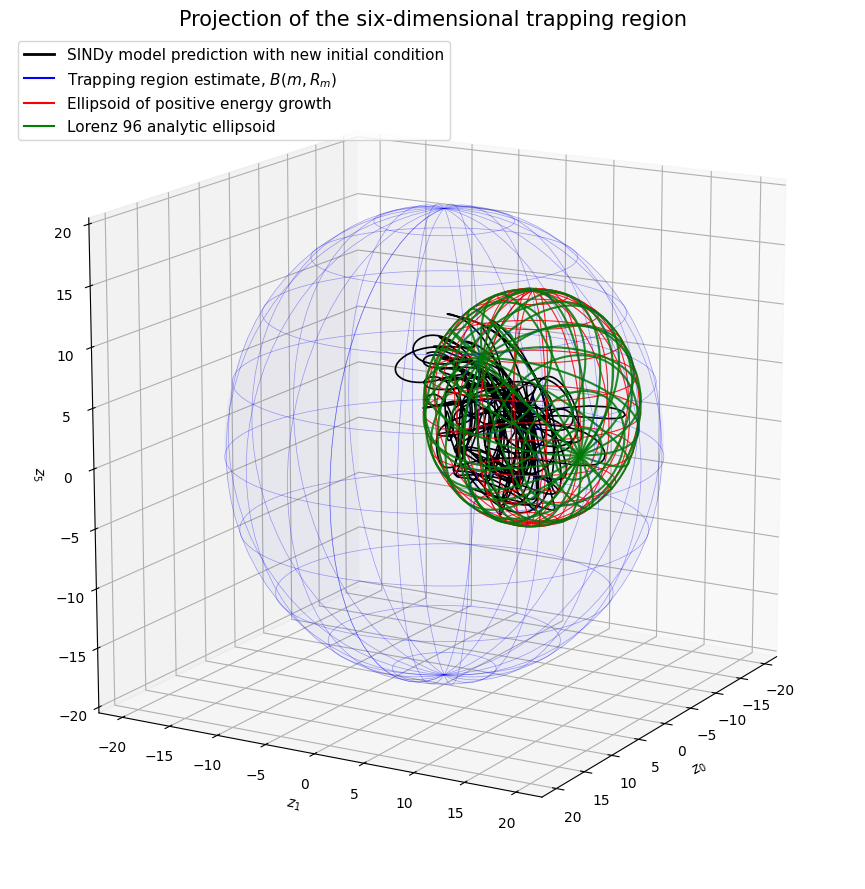

In [7]:
# Construct the identified and analytic geometries at the learned shift.
opt_m = sindy_opt.m_history_[-1]
geometry = energy_geometry(C, L, Q, opt_m)
analytic_geometry = energy_geometry(C_true, L_true, Q_true, opt_m)
analytic_origin_geometry = energy_geometry(C_true, L_true, Q_true, np.zeros(r))
R_pred = geometry["radius"]

# Verify the certificate and the analytic reference before plotting.
assert Q_sum < 1e-10
assert geometry["eigenvalues"][-1] < 0
np.testing.assert_allclose(analytic_origin_geometry["As"], -np.eye(r), atol=1e-14)
np.testing.assert_allclose(analytic_origin_geometry["radius"], abs(F) * np.sqrt(r))
np.testing.assert_allclose(float(Rm), R_pred, rtol=1e-9)

# Sample the full-dimensional ellipsoid boundary and check its energy-growth level.
boundary_rng = np.random.default_rng(12)
directions = boundary_rng.normal(size=(100, r))
directions /= np.linalg.norm(directions, axis=1, keepdims=True)
for region in (geometry, analytic_geometry):
    boundary = region["center"] + directions @ np.linalg.cholesky(region["shape"]).T
    growth = np.einsum("ti,ij,tj->t", boundary, region["As"], boundary)
    growth += boundary @ region["d"]
    np.testing.assert_allclose(growth, 0, atol=1e-10)

print("Global structural certificate (within numerical tolerance):", True)
print("Analytic trapping radius at m = 0 =", analytic_origin_geometry["radius"])
print("Identified trapping radius at learned m =", R_pred)
print("Analytic trapping radius at learned m =", analytic_geometry["radius"])

# Make the 3D illustration from the full 6D operators.
trapping_region_lorenz96(x_test_pred, geometry, analytic_geometry)
plt.show()

## Some of these plots are different looking than in the Lorenz example

The system now has six state variables, so the time-series figure has twelve
panels and the Lissajous figure has thirty-six panels. The trapping-region figure
shows three coordinates of a six-dimensional geometry, with
$\mathbf{z}=\mathbf{V}^{T}(\mathbf{x}-\mathbf{m})$. All regression errors,
constraint checks, and stability eigenvalues are calculated in the full state
space. A trajectory that lies inside a projected ball need not lie inside the
full six-dimensional ball; we therefore check the full norm below.

The derivative comparison evaluates the model on the true testing states. The
state comparison instead integrates the learned model autonomously, so accurate
derivative predictions do not imply pointwise agreement over the entire testing
interval.

# Trajectories starting outside the trapping region

To complement the geometric illustration, we initialize four additional
trajectories outside the identified trapping ball, at twice its estimated radius.
For each initial condition, we integrate both the learned and analytic systems.
The plots show their full six-dimensional distances from the learned shift and
their shifted energies, using the red/black comparison style of the original
example. We also report entry times and check that the learned trajectories
remain inside after entering the ball.

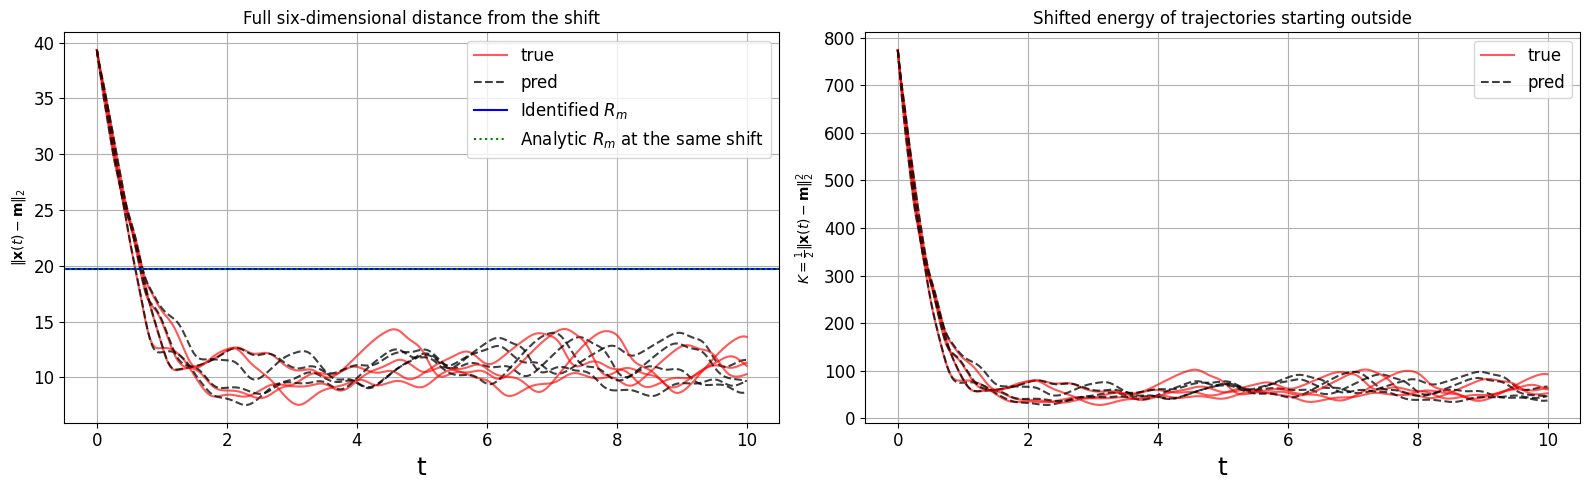

Initial distances / Rm = [2. 2. 2. 2.]
Entry times into the identified trapping ball = [0.6, 0.7, 0.67, 0.71]
Remain inside after entry = [True, True, True, True]
Maximum predicted energy growth outside the ball = -408.10453780599687


In [8]:
# Use a separate random generator so this check does not change train/test data.
outside_rng = np.random.default_rng(24)
n_outside = 4
outside_directions = outside_rng.normal(size=(n_outside, r))
outside_directions /= np.linalg.norm(outside_directions, axis=1, keepdims=True)
outside_initial_conditions = opt_m + 2 * R_pred * outside_directions
t_outside = np.arange(0, 10 + dt, dt)

outside_pred = np.array([
    model.simulate(x0, t_outside, integrator_kws=integrator_keywords)
    for x0 in outside_initial_conditions
])
outside_true = []
for x0 in outside_initial_conditions:
    solution = solve_ivp(
        lorenz96, (t_outside[0], t_outside[-1]), x0,
        t_eval=t_outside, args=(F,), **integrator_keywords,
    )
    assert solution.success
    outside_true.append(solution.y.T)
outside_true = np.asarray(outside_true)

radii_pred = np.linalg.norm(outside_pred - opt_m, axis=2)
radii_true = np.linalg.norm(outside_true - opt_m, axis=2)
energy_pred = 0.5 * radii_pred ** 2
energy_true = 0.5 * radii_true ** 2
velocity_pred = np.array([model.predict(trajectory) for trajectory in outside_pred])
energy_rate_pred = np.sum((outside_pred - opt_m) * velocity_pred, axis=2)
outside_mask = radii_pred > R_pred * (1 + 1e-8)
max_outside_energy_rate = np.max(energy_rate_pred[outside_mask])

entry_times = []
stayed_inside = []
for radius in radii_pred:
    entered = np.flatnonzero(radius <= R_pred)
    entry_times.append(t_outside[entered[0]] if entered.size else np.nan)
    stayed_inside.append(
        bool(entered.size and np.all(radius[entered[0]:] <= R_pred * (1 + 1e-8)))
    )

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for i in range(n_outside):
    axes[0].plot(t_outside, radii_true[i], "r", alpha=0.65,
                 label="true" if i == 0 else None)
    axes[0].plot(t_outside, radii_pred[i], "k--", alpha=0.75,
                 label="pred" if i == 0 else None)
    axes[1].plot(t_outside, energy_true[i], "r", alpha=0.65,
                 label="true" if i == 0 else None)
    axes[1].plot(t_outside, energy_pred[i], "k--", alpha=0.75,
                 label="pred" if i == 0 else None)
axes[0].axhline(R_pred, color="b", label=r"Identified $R_m$")
axes[0].axhline(analytic_geometry["radius"], color="g", linestyle=":",
                label=r"Analytic $R_m$ at the same shift")
axes[0].set(ylabel=r"$\|\mathbf{x}(t)-\mathbf{m}\|_2$",
            title="Full six-dimensional distance from the shift")
axes[1].set(ylabel=r"$K=\frac{1}{2}\|\mathbf{x}(t)-\mathbf{m}\|_2^2$",
            title="Shifted energy of trajectories starting outside")
for ax in axes:
    ax.set_xlabel("t", fontsize=18)
    ax.grid(True)
    ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
fig.tight_layout()
plt.show()

print("Initial distances / Rm =", radii_pred[:, 0] / R_pred)
print("Entry times into the identified trapping ball =", np.round(entry_times, 2).tolist())
print("Remain inside after entry =", stayed_inside)
print("Maximum predicted energy growth outside the ball =", max_outside_energy_rate)
assert np.isfinite(outside_pred).all()
assert np.all(np.isfinite(entry_times)) and all(stayed_inside)
assert max_outside_energy_rate < 0

## Key result: the 6D SINDy model preserves the quadratic energy structure and admits a trapping region

The identified model reproduces the dominant Lorenz 96 coefficients and the
state-space geometry, satisfies the quadratic energy constraints to numerical
precision, and has a negative definite shifted energy matrix. The projected
identified and analytic ellipsoids can be compared directly, and the additional
full-state simulations verify entry into the trapping ball for four independent
initial conditions outside it.

# Identifying Lorenz 96 from noisy observations

We now repeat the identification experiment with 1% and 5% observation noise,
and compare both cases with the clean-data result. For each state variable, the
noise level is defined by

$$
\text{Noise level}_i\ (\%)
=\frac{\operatorname{std}(\varepsilon_i)}
       {\operatorname{std}(x_{\mathrm{train},i})}\times100\%.
$$

We generate a zero-mean Gaussian noise realization, normalize its sample standard
deviation separately in each variable, and scale the same realization to the two
noise levels. Only the training observations are perturbed. The independent
testing trajectory remains clean, and differentiation uses the same finite
differences as before, without smoothing or access to analytic training derivatives.
The experiment uses one reproducible noise realization at each level.

In [9]:
# Match the realized standard-deviation ratio in each of the six variables.
noise_rng = np.random.default_rng(2026)
unit_noise = noise_rng.normal(size=x_train.shape)
unit_noise -= np.mean(unit_noise, axis=0, keepdims=True)
unit_noise /= np.std(unit_noise, axis=0, ddof=0, keepdims=True)
signal_std = np.std(x_train, axis=0, ddof=0)
noise_inputs = {"Clean": x_train}
for noise_label, noise_fraction in (("1%", 0.01), ("5%", 0.05)):
    noise_inputs[noise_label] = x_train + noise_fraction * signal_std * unit_noise
    measured_ratios = np.std(noise_inputs[noise_label] - x_train, axis=0) / signal_std
    np.testing.assert_allclose(measured_ratios, noise_fraction, rtol=1e-12, atol=1e-14)
    print(noise_label, "realized noise levels (%) =", np.round(100 * measured_ratios, 8))
np.testing.assert_allclose(
    noise_inputs["5%"] - x_train, 5 * (noise_inputs["1%"] - x_train), atol=1e-14
)

1% realized noise levels (%) = [1. 1. 1. 1. 1. 1.]
5% realized noise levels (%) = [5. 5. 5. 5. 5. 5.]


### Comparing trapping SINDy with naive SINDy

For each dataset we compare the globally constrained Trapping SINDy model with a
naive SINDy model using the default `STLSQ()` optimizer (threshold 0.1, ridge
parameter 0.05, and the default final unbiasing step). Both models use the same
constant/linear/quadratic library, training observations, and finite differences.
Trapping SINDy retains the hyperparameters of the clean experiment; neither model
is retuned between noise levels. The clean Trapping SINDy fit is reused.

For the baseline, we follow the simulated-annealing example in
`trapping_extended.ipynb`, minimizing the largest eigenvalue of the shifted
$\mathbf{A}^{S}$. Each component of $\mathbf{m}$ is searched in $[-1000,1000]$,
with 500 annealing iterations and a fixed random seed. The zero shift is retained
if it has a lower objective than the annealing result. This is a numerical search
for a shift, rather than an additional constraint on the baseline coefficients.

The four-panel figure compares coefficient accuracy, derivative accuracy on the
same clean test states, the largest stability eigenvalue, and the identified
certified radius: global certificates report $R_m$, while local certificates
report the outer stability radius $\rho_+$. These are distinct quantities,
identified explicitly in the radius-panel legend. Coefficient errors are shown as percentages, and the derivative
errors and the radius panel use logarithmic scales. The derivative reference is the same finite
difference reference used above. A radius is plotted only when its criterion
is satisfied; otherwise it is marked N/A. The caption identifies the radius
certificates for each model.

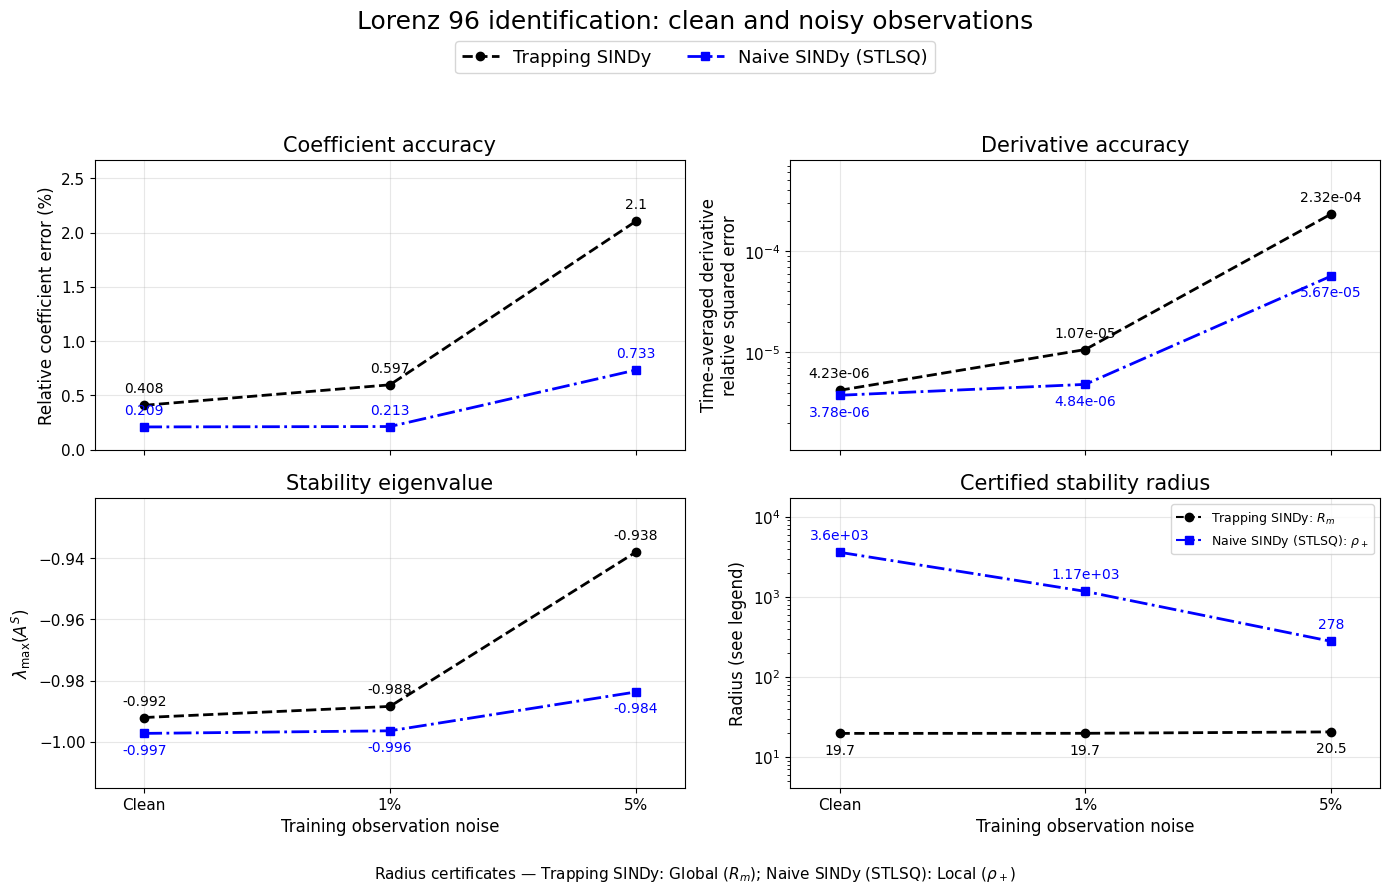

In [10]:
comparison_models = {}
comparison_diagnostics = {}
baseline_annealing = {}
comparison_records = []
derivative_valid = np.all(np.isfinite(xdot_test), axis=1)
test_derivative_ref = xdot_test[derivative_valid]
derivative_ref_squared = np.sum(test_derivative_ref ** 2, axis=1)
assert np.all(derivative_ref_squared > 0)

for noise_label, observations in noise_inputs.items():
    if noise_label == "Clean":
        trapping_model = model
        fit_warnings = []
    else:
        trapping_optimizer = ps.TrappingSR3(
            method="global", _n_tgts=r, _include_bias=True,
            reg_weight_lam=reg_weight_lam, eta=eta, alpha_m=alpha_m,
            max_iter=max_iter, gamma=-1, m0=np.zeros(r), verbose=False,
        )
        trapping_model = ps.SINDy(
            optimizer=trapping_optimizer,
            feature_library=ps.PolynomialLibrary(include_bias=True),
            differentiation_method=ps.FiniteDifference(drop_endpoints=True),
        )
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            trapping_model.fit(observations, t=t)

    baseline_model = ps.SINDy(
        optimizer=ps.STLSQ(),
        feature_library=ps.PolynomialLibrary(include_bias=True),
        differentiation_method=ps.FiniteDifference(drop_endpoints=True),
    )
    baseline_model.fit(observations, t=t)
    for model_name, fitted_model in (
        ("Trapping SINDy", trapping_model), ("Naive SINDy (STLSQ)", baseline_model)
    ):
        key = (noise_label, model_name)
        comparison_models[key] = fitted_model
        fitted_Xi, fitted_C, fitted_L, fitted_Q = comparison_operators(fitted_model)
        if model_name == "Trapping SINDy":
            fitted_m = fitted_model.optimizer.m_history_[-1].copy()
        else:
            fitted_m, annealing_result = anneal_baseline_shift(fitted_L, fitted_Q)
            baseline_annealing[noise_label] = annealing_result
        diagnostics = comparison_stability(fitted_C, fitted_L, fitted_Q, fitted_m)
        diagnostics.update({"C": fitted_C, "L": fitted_L, "Q": fitted_Q})
        comparison_diagnostics[key] = diagnostics
        derivative_pred = fitted_model.predict(x_test)[derivative_valid]
        comparison_records.append({
            "Data": noise_label,
            "Model": model_name,
            "Coefficient error": np.linalg.norm(fitted_Xi - Xi_lorenz96) / np.linalg.norm(Xi_lorenz96),
            "Derivative error": np.mean(
                np.sum((test_derivative_ref - derivative_pred) ** 2, axis=1)
                / derivative_ref_squared
            ),
            "Max eigenvalue": diagnostics["max_eigenvalue"],
            "Stability radius": diagnostics["outer_radius"] if diagnostics["certificate"] == "Local" else diagnostics["radius"],
            "Certificate": diagnostics["certificate"],
        })
    for warning in fit_warnings:
        print("Trapping fit warning:", warning.message)

comparison_table = pd.DataFrame(comparison_records)
np.testing.assert_allclose(comparison_table.iloc[0]["Coefficient error"], coef_pred)
np.testing.assert_allclose(comparison_table.iloc[0]["Derivative error"], deriv_error_mean)
np.testing.assert_allclose(comparison_table.iloc[0]["Stability radius"], R_pred)
plot_noise_comparison(comparison_table)
plt.show()

### A Lyapunov-time prediction window

We use the largest Lyapunov exponent of the analytic six-dimensional Lorenz 96
system to set the time scale $T_L=1/\lambda_1$. The prediction comparison starts
from the clean independent test state at $t=10$ and runs for $10T_L$.
The exponent estimate sets the plotting horizon only; it is not used to fit or
select either data-driven model.

In [11]:
# Check the variational equation independently against a directional difference.
lyap_rng = np.random.default_rng(2027)
tangent_probe = lyap_rng.normal(size=r)
tangent_probe /= np.linalg.norm(tangent_probe)
state_probe = x_test[len(t) // 2]
directional_difference = (
    lorenz96(0, state_probe + 1e-6 * tangent_probe, F)
    - lorenz96(0, state_probe - 1e-6 * tangent_probe, F)
) / 2e-6
np.testing.assert_allclose(
    lorenz96_tangent(state_probe, tangent_probe), directional_difference,
    rtol=1e-7, atol=1e-7,
)




largest_lyapunov, lyapunov_half_estimates = estimate_lorenz96_lyapunov(x_train[-1], F)
assert largest_lyapunov > 0
lyapunov_time = 1 / largest_lyapunov
prediction_lyapunov_times = 10.0
prediction_horizon = prediction_lyapunov_times * lyapunov_time

# Prediction with 5% noise

Finally, we compare autonomous predictions from the two models fitted to the 5%
noisy training observations. The clean analytic trajectory is shown in red,
Trapping SINDy in black dashed lines, and naive SINDy in blue dash-dot lines. All
six state variables are displayed over ten Lyapunov times. Both
models start from exactly the same clean held-out initial state.

We integrate the extracted polynomial operators directly, after checking them
against each model's `predict` method. This gives the same autonomous vector
fields without repeatedly constructing the feature library during integration.

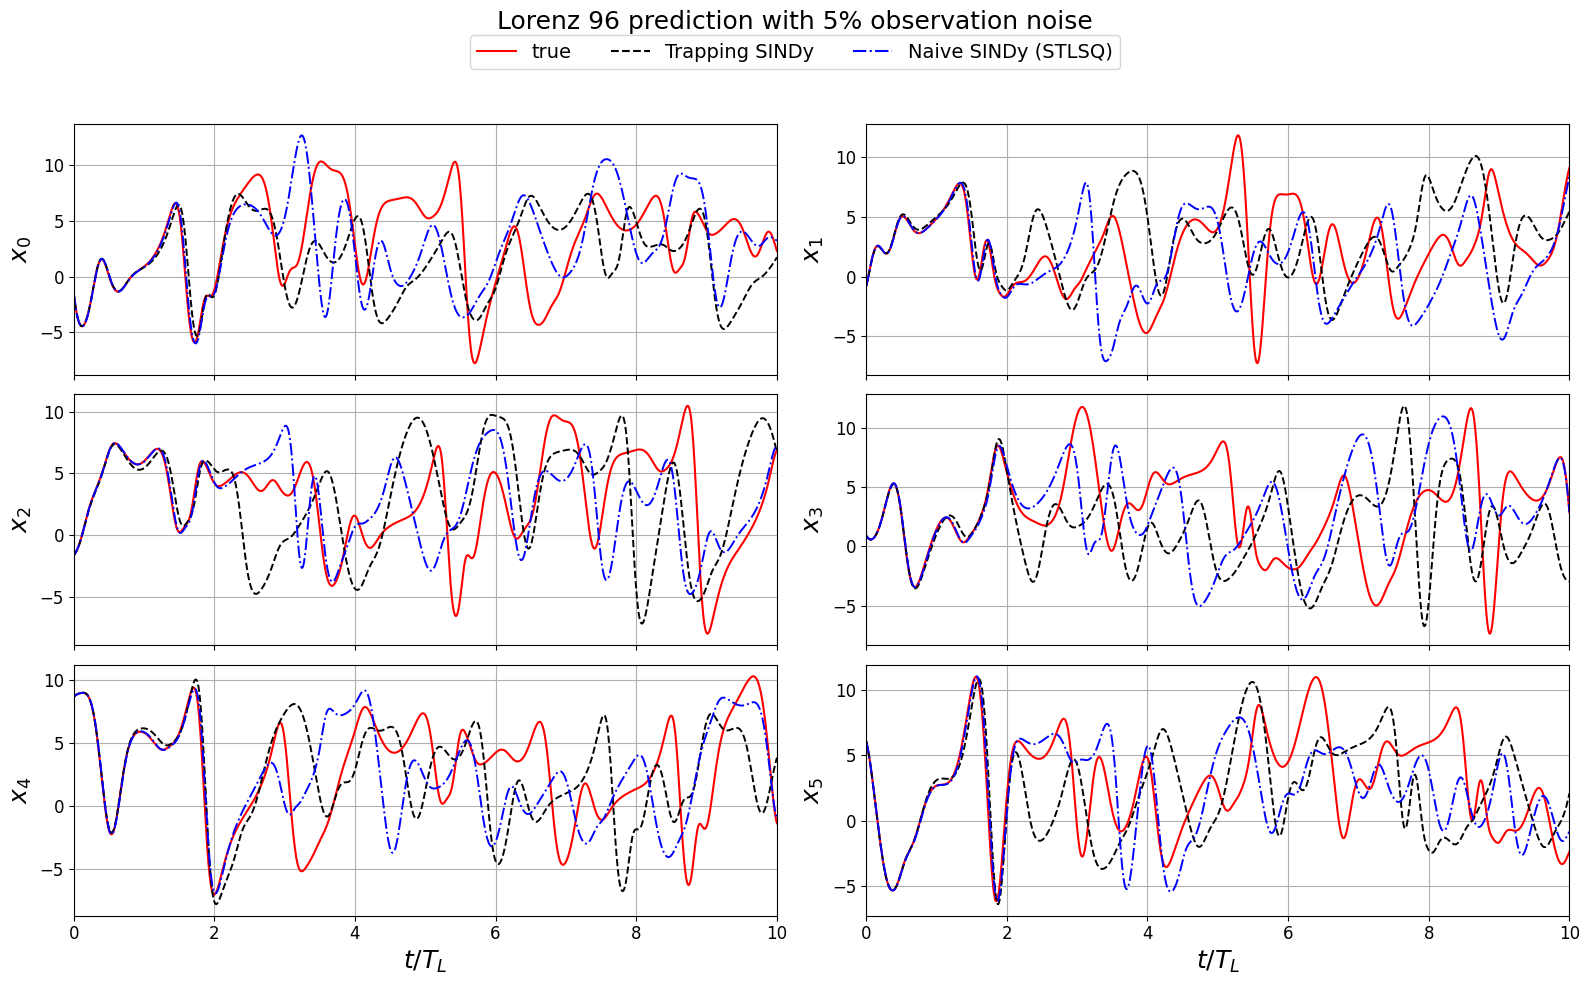

In [12]:
forecast_start_index = int(round(10 / dt))
forecast_initial_state = x_test[forecast_start_index].copy()
n_forecast_steps = int(np.ceil(prediction_horizon / dt))
t_forecast = np.linspace(0, prediction_horizon, n_forecast_steps + 1)
forecast_solver_options = dict(method="DOP853", rtol=1e-10, atol=1e-12)
forecast_true_solution = solve_ivp(
    lorenz96, (0, prediction_horizon), forecast_initial_state,
    t_eval=t_forecast, args=(F,), **forecast_solver_options,
)
assert forecast_true_solution.success
forecast_solutions = {}
for model_name in ("Trapping SINDy", "Naive SINDy (STLSQ)"):
    diagnostics = comparison_diagnostics[("5%", model_name)]
    forecast_C, forecast_L, forecast_Q = (diagnostics[name] for name in ("C", "L", "Q"))

    np.testing.assert_allclose(
        identified_rhs(0, forecast_initial_state, forecast_C, forecast_L, forecast_Q),
        comparison_models[("5%", model_name)].predict(forecast_initial_state[None])[0],
        rtol=1e-12, atol=1e-12,
    )
    solution = solve_ivp(
        identified_rhs, (0, prediction_horizon), forecast_initial_state,
        t_eval=t_forecast, args=(forecast_C, forecast_L, forecast_Q),
        **forecast_solver_options,
    )
    forecast_solutions[model_name] = solution
    if not solution.success:
        print(model_name, "integration stopped at", solution.t[-1] / lyapunov_time,
              "Lyapunov times:", solution.message)

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(t_forecast / lyapunov_time, forecast_true_solution.y[i], "r", linewidth=1.5)
    for model_name, style in (("Trapping SINDy", "k--"), ("Naive SINDy (STLSQ)", "b-.")):
        solution = forecast_solutions[model_name]
        ax.plot(solution.t / lyapunov_time, solution.y[i], style, linewidth=1.4)
        if not solution.success:
            ax.axvline(solution.t[-1] / lyapunov_time, color=style[0], linestyle=":")
    ax.set_ylabel(rf"$x_{i}$", fontsize=18)
    ax.set_xlim(0, prediction_lyapunov_times)
    ax.grid(True)
    ax.tick_params(labelsize=12)
for ax in axes[-1]:
    ax.set_xlabel(r"$t/T_L$", fontsize=18)
fig.legend(handles=[
    Line2D([], [], color="r", label="true"),
    Line2D([], [], color="k", linestyle="--", label="Trapping SINDy"),
    Line2D([], [], color="b", linestyle="-.", label="Naive SINDy (STLSQ)"),
], loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=3, fontsize=14)
fig.suptitle("Lorenz 96 prediction with 5% observation noise", fontsize=18)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

# Sparse identification with local trapping SINDy

We repeat the local experiment with the built-in `l1`, `l2`, `weighted_l1`, and
`weighted_l2` penalties. The original global group and all STLSQ baselines are
retained. The local energy penalties remain $\alpha=10^{20}$ and $\beta=10^{-10}$,
with $\eta=1000$, $\alpha_m=100$, $\gamma=-1$, a zero initial shift, and at most
5000 iterations. No hard energy constraints, support masks, or coefficient
pruning are used.

We select penalties separately for Clean, 1%, and 5% observations using only the
first 80% of the training trajectory for fitting and the remaining 20% for
validation, separated by a two-sample gap. Derivatives on each block are computed
from that block alone. The independent testing trajectory and the analytic
coefficient support are not consulted during selection.

For clean data, we choose the fewest effective terms among converged candidates
with a local certificate and at most 2% aggregate validation derivative NRMSE;
validation accuracy breaks ties. For noisy data, minimum validation loss takes
priority, with sparsity used only to break numerical ties. The selected penalty
is then refitted on the complete training trajectory. The unregularized local
fits are retained as references.

The parameter called strength below is the penalty weight per fitting sample;
the native weight is multiplied by the number of valid fitting samples. Weighted
penalties either scale by feature standard deviations (squared for L2) or use
equal nonconstant weights. Their constant forcing coefficients are fitted freely
without a penalty. Effective terms use the same fixed tolerance
$|\xi|>10^{-3}$ in every model. This tolerance is only for counting and support
diagnostics: small coefficients are never removed from the model or its
stability calculation.

To keep the search inexpensive, we QR-compress the least-squares rows before
calling the native local optimizer. The coefficients, physical local penalties,
and built-in L1/L2 terms remain in their original units; the omitted part of the
least-squares loss is constant in the coefficients. CVXPY's installed Clarabel
backend is selected explicitly to avoid inaccurate QP solves observed with the
default backend at these energy-penalty scales. Unconverged or uncertified
candidates are excluded.

Implementation note: this checkout uses different cyclic-tensor normalization
in the zero-weight and CVXPY update branches (the CVXPY branch omits a factor of
three before squaring). We retain both native branches unchanged and recompute
every local certificate from the final physical coefficients.

In [13]:
local_alpha = 1e20
local_beta = 1e-10
local_zero_tolerance = 1e-3
local_selected_models = {}
local_selected_diagnostics = {}
local_regularization_paths = {}
local_regularization_choices = {}
local_unregularized_models = {}
local_sparsity_records = []

# Every choice is fixed before scoring any model on the independent test data.
for noise_label, observations in noise_inputs.items():
    fitted, diagnostics, path, choice = search_local_regularization(
        observations, t, clean=(noise_label == "Clean"),
        zero_tolerance=local_zero_tolerance,
    )
    local_selected_models[noise_label] = fitted
    local_selected_diagnostics[noise_label] = diagnostics
    local_regularization_paths[noise_label] = path
    local_regularization_choices[noise_label] = choice
    reference, reference_warnings = fit_regularized_local(observations, t, "l1", 0.0)
    local_unregularized_models[noise_label] = reference
    local_sparsity_records.append({
        "Data": noise_label, "Regularizer": choice["Regularizer"],
        "Weighting": choice["Weighting"], "Strength": choice["Strength"],
        "Validation loss": choice["Validation loss"],
        "Selected terms": int(np.count_nonzero(np.abs(fitted.coefficients()) > local_zero_tolerance)),
        "Unregularized terms": int(np.count_nonzero(np.abs(reference.coefficients()) > local_zero_tolerance)),
        "Baseline terms": int(np.count_nonzero(
            np.abs(comparison_models[(noise_label, "Naive SINDy (STLSQ)")].coefficients()) > local_zero_tolerance
        )),
    })

local_sparsity_summary = pd.DataFrame(local_sparsity_records)
local_unregularized_records = []
for noise_label, reference in local_unregularized_models.items():
    diagnostics = fitted_local_diagnostics(reference)
    prediction = reference.predict(x_test)[derivative_valid]
    local_unregularized_records.append({
        "Data": noise_label,
        "Coefficient error": np.linalg.norm(reference.coefficients().T - Xi_lorenz96) / np.linalg.norm(Xi_lorenz96),
        "Derivative error": np.mean(np.sum((test_derivative_ref - prediction) ** 2, axis=1) / derivative_ref_squared),
        "Max eigenvalue": diagnostics["max_eigenvalue"],
        "Local stability radius (rho_plus)": diagnostics["outer_radius"],
        "Effective terms": int(np.count_nonzero(np.abs(reference.coefficients()) > local_zero_tolerance)),
    })
local_unregularized_reference = pd.DataFrame(local_unregularized_records)
local_model = local_selected_models["Clean"]
local_optimizer = local_model.optimizer
assert local_optimizer.method == "local" and not local_optimizer.use_constraints
assert all(status == cp.OPTIMAL for status in local_optimizer.solver_statuses_)

## Regularization paths and sparsity

The first three panels show the training-only validation paths. Red stars mark
the regularization configurations selected by the training-only validation
procedure. The fourth panel compares effective term counts after full-data
refitting, including the unregularized local models and unchanged STLSQ baselines.
L2 is included as a shrinkage control, rather than assumed to create zeros.

The next three figures compare the analytic, selected local, and naive STLSQ
supports separately for Clean, 1%, and 5% observations. Each coefficient is a
2-by-2 tile: analytic at top left, local at top right, and naive STLSQ at bottom
left; the bottom-right position is unused. A colored subcell indicates an
effective term with $|\xi|>10^{-3}$, while white indicates an absent term or the
unused position. The fixed positions make additional and missing terms visible
without superimposing colors. The analytic support is inspected only after
selection and is never imposed during fitting.


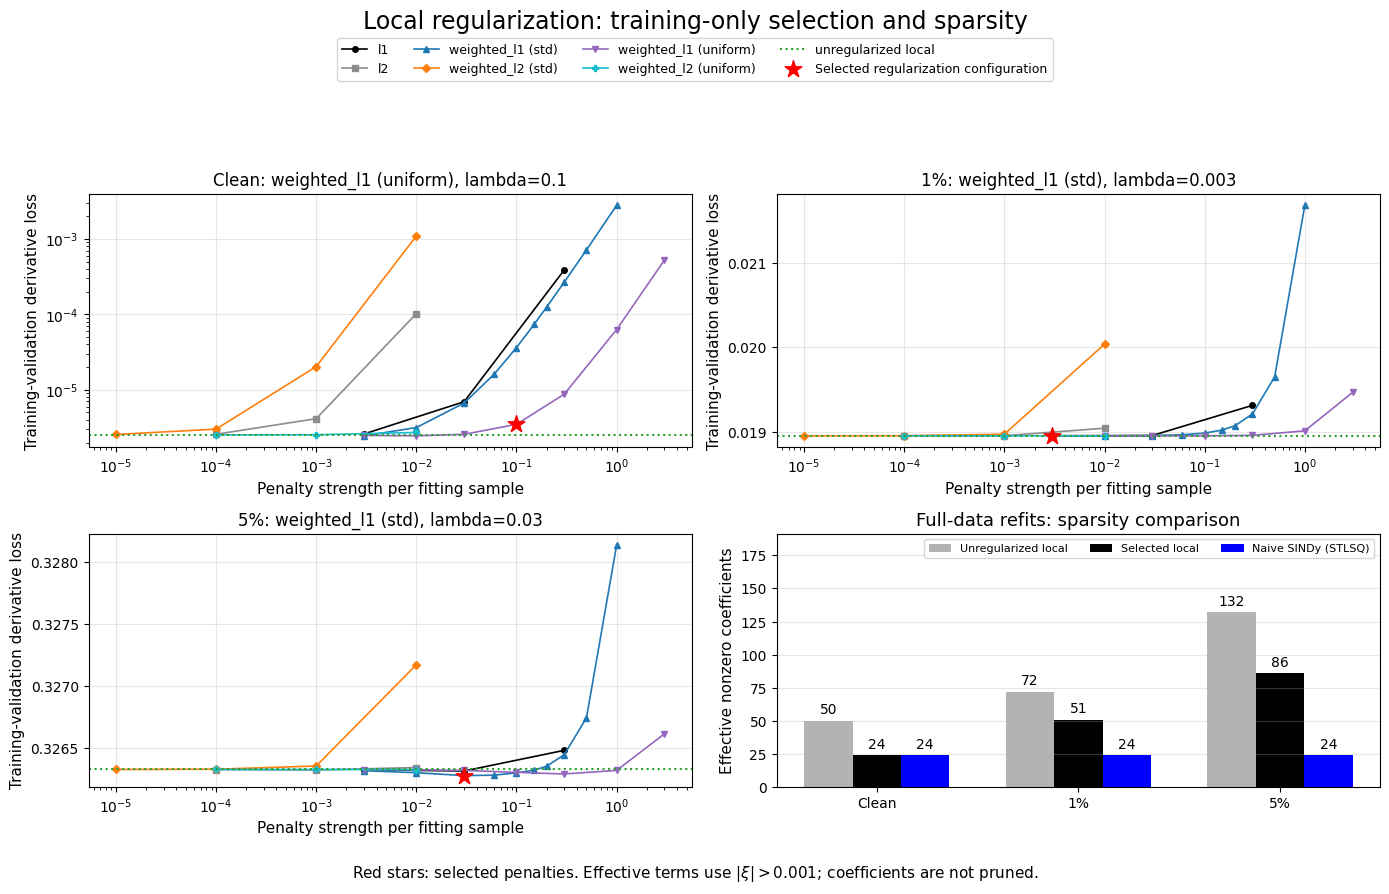

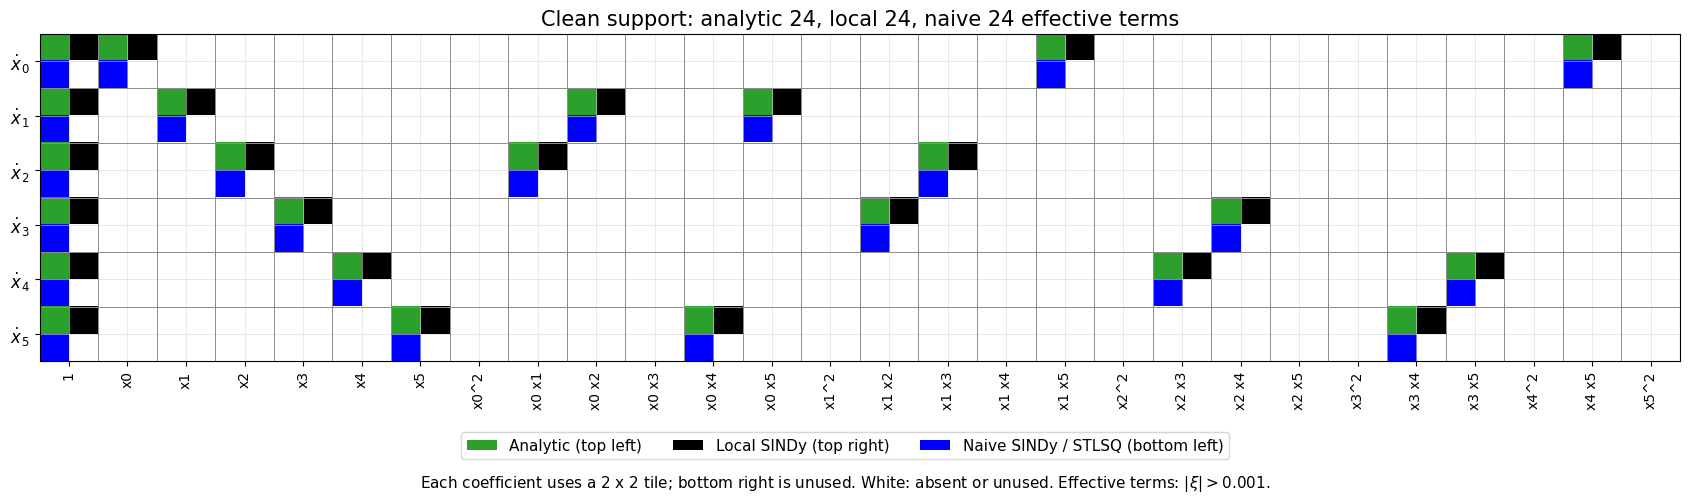

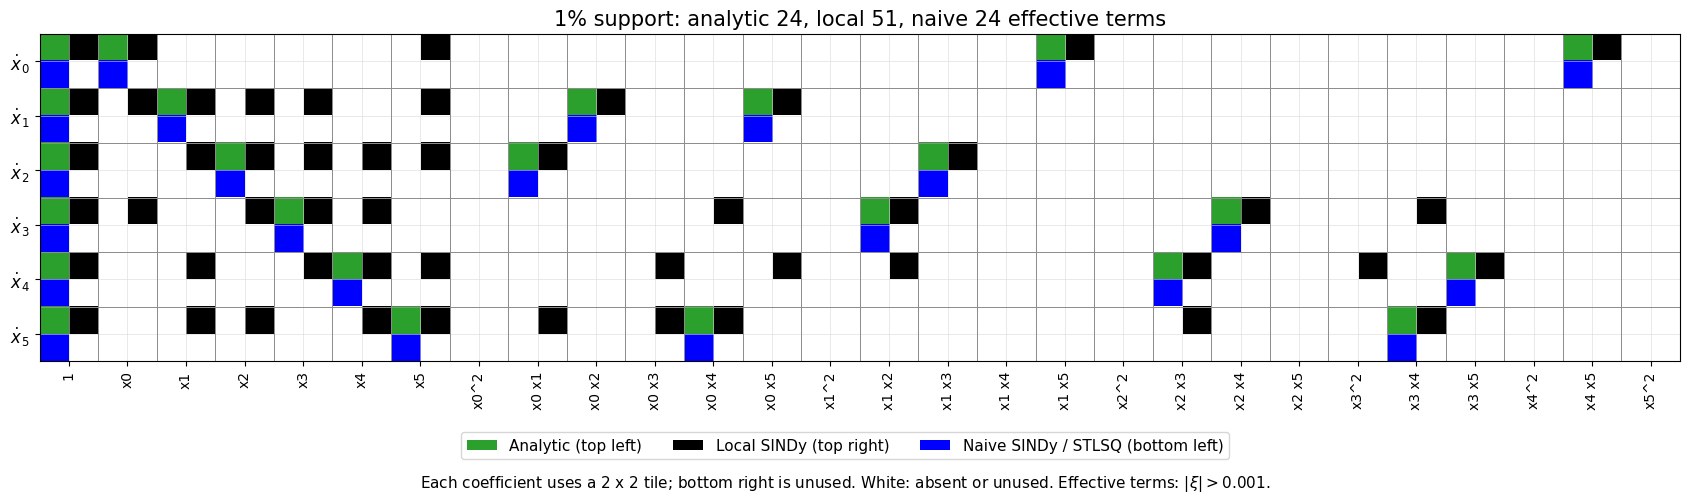

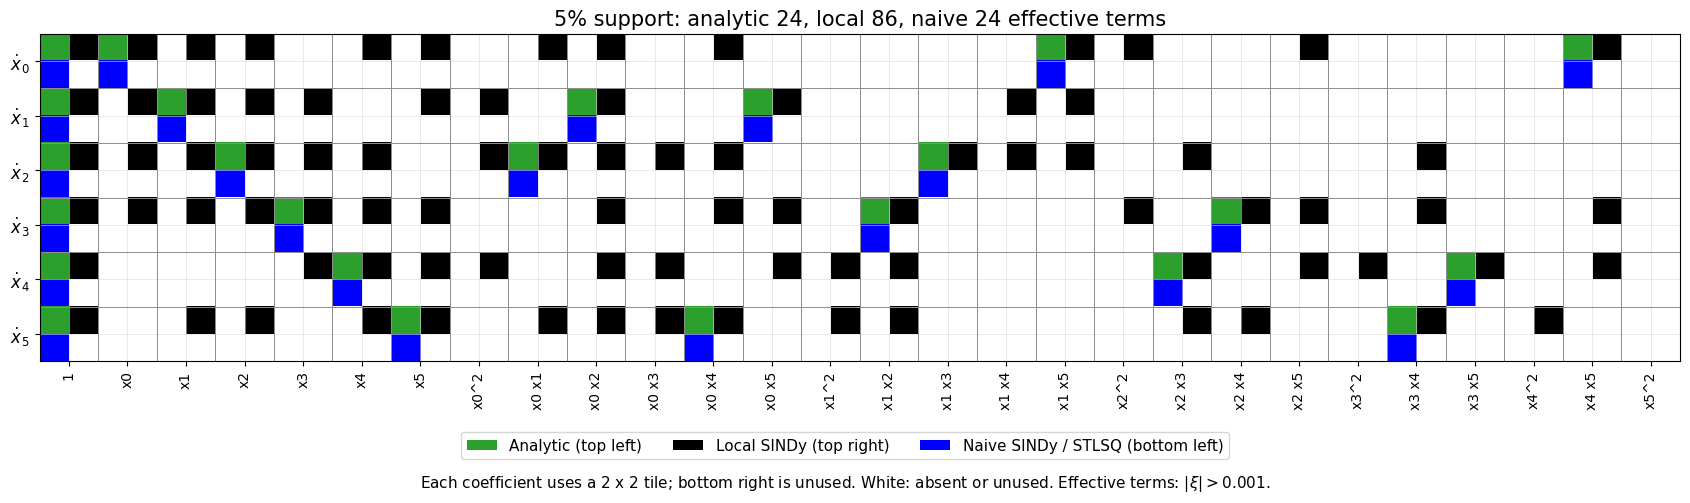

In [14]:
plot_local_regularization_search(
    local_regularization_paths, local_regularization_choices,
    local_sparsity_summary, local_zero_tolerance,
)
plt.show()

for noise_label in ("Clean", "1%", "5%"):
    selected = local_selected_models[noise_label]
    baseline = comparison_models[(noise_label, "Naive SINDy (STLSQ)")]
    plot_local_support_comparison(
        selected, baseline, Xi_lorenz96, selected.feature_library.get_feature_names(),
        local_zero_tolerance, noise_label,
    )
    plt.show()


## The selected clean local model

We now repeat the full clean-data diagnostics with the selected regularized model.

In [15]:
local_model.print()
clean_choice = local_regularization_choices["Clean"]
print("Selected native regularizer:", local_optimizer.regularizer)
print("Weighting:", clean_choice["Weighting"], "| penalty strength per sample:", clean_choice["Strength"])
print("Effective coefficients (|xi| > 1e-3) =", int(np.count_nonzero(np.abs(local_model.coefficients()) > local_zero_tolerance)))
print("Number of local optimizer iterations =", len(local_optimizer.history_))

local_Xi, local_C, local_L, local_Q = comparison_operators(local_model)
local_shift = local_optimizer.m_history_[-1].copy()
local_clean_diagnostics = local_selected_diagnostics["Clean"]
local_xdot_test_pred = local_model.predict(x_test)
local_x_train_pred = simulate_polynomial_trajectory(local_clean_diagnostics, x_train[0], t)
local_x_test_pred = simulate_polynomial_trajectory(local_clean_diagnostics, x_test[0], t)

(x0)' = 7.947 1 + -0.990 x0 + -0.001 x0 x4 + 0.997 x1 x5 + -0.001 x3 x4 + -0.997 x4 x5
(x1)' = 7.946 1 + -0.990 x1 + 0.998 x0 x2 + -0.998 x0 x5 + -0.001 x1 x4 + -0.001 x1 x5 + 0.001 x4^2
(x2)' = 7.957 1 + -0.992 x2 + -0.998 x0 x1 + 0.998 x1 x3 + -0.001 x2 x5
(x3)' = 7.949 1 + -0.992 x3 + -0.998 x1 x2 + 0.997 x2 x4 + 0.001 x2 x5
(x4)' = 7.932 1 + -0.991 x4 + 0.001 x0^2 + 0.001 x0 x3 + 0.001 x1^2 + -0.001 x1 x4 + -0.997 x2 x3 + 0.996 x3 x5
(x5)' = 7.939 1 + -0.990 x5 + 0.997 x0 x4 + 0.001 x1^2 + 0.001 x2^2 + -0.001 x2 x3 + -0.996 x3 x4
Selected native regularizer: weighted_l1
Weighting: uniform | penalty strength per sample: 0.1
Effective coefficients (|xi| > 1e-3) = 24
Number of local optimizer iterations = 2


## Predictions and optimization progress of the regularized local model

We use the same time-series and Lissajous layouts as in the global experiment,
followed by the coefficient/shift progress and all six stability eigenvalues.
Autonomous trajectories are integrated from the extracted polynomial operators,
which are checked against the fitted model's `predict` method.

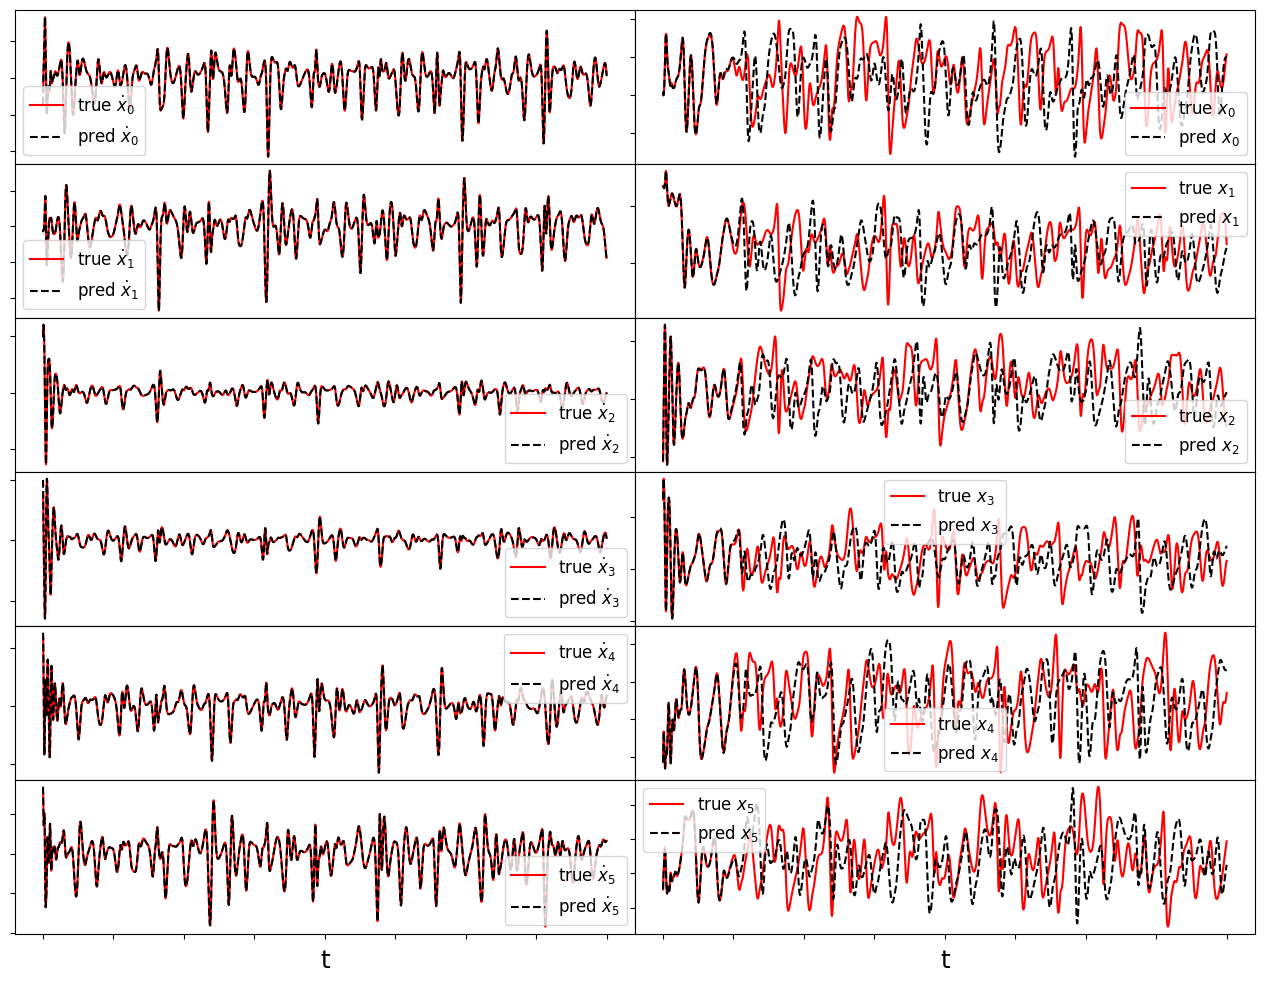

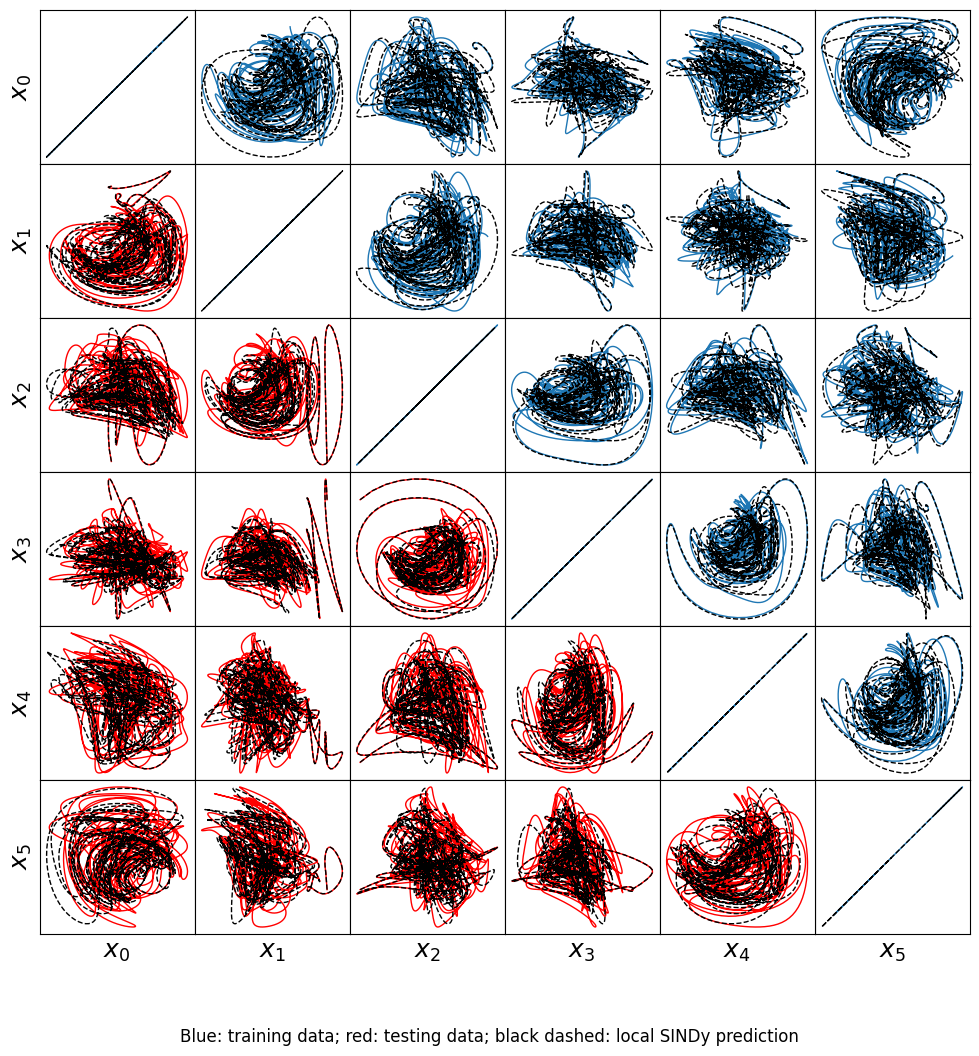

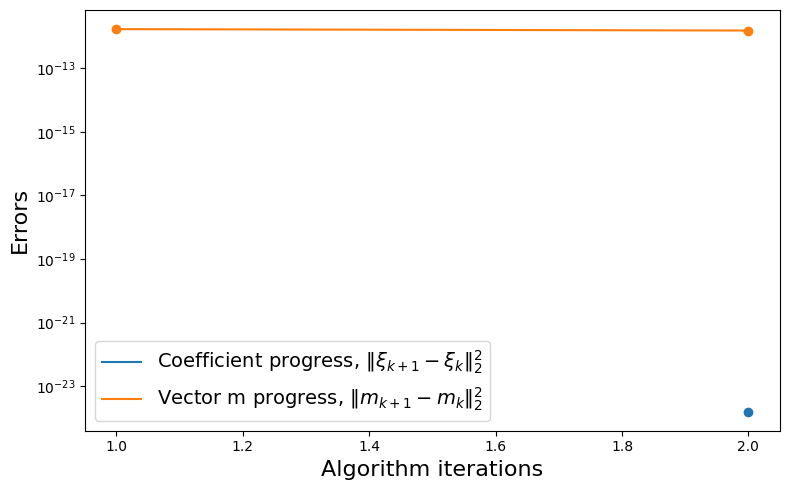

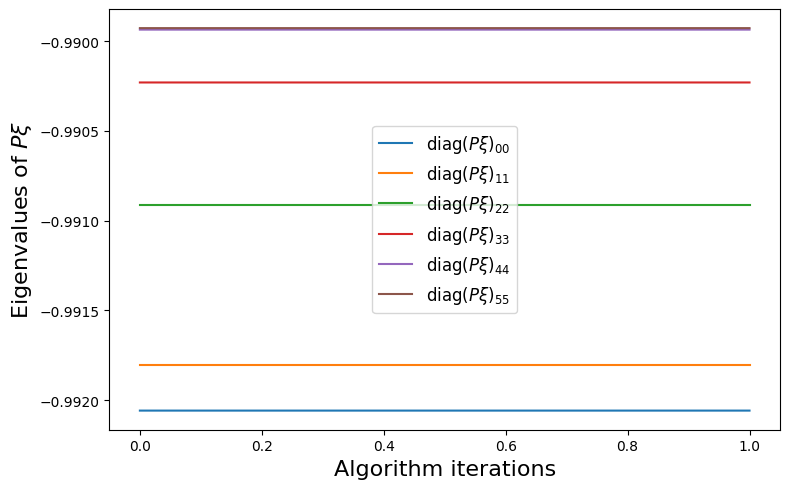

In [16]:
make_fits(r, t, xdot_test, local_xdot_test_pred, x_test, local_x_test_pred, "lorenz96_local")
plt.gcf().set_size_inches(16, 12)
plt.show()

make_lissajou(r, x_train, x_test, local_x_train_pred, local_x_test_pred, "lorenz96_local")
plt.gcf().set_size_inches(12, 12)
plt.gcf().text(
    0.5, 0.02,
    "Blue: training data; red: testing data; black dashed: local SINDy prediction",
    ha="center", fontsize=12,
)
plt.show()

plot_optimizer_progress(local_optimizer)
plt.show()

In [17]:
local_coef_error = np.linalg.norm(local_Xi - Xi_lorenz96) / np.linalg.norm(Xi_lorenz96)
local_derivative_error = np.nanmean(
    np.sum((xdot_test - local_xdot_test_pred) ** 2, axis=1) / np.sum(xdot_test ** 2, axis=1)
)
local_trajectory_error = np.linalg.norm(x_test - local_x_test_pred) / np.linalg.norm(x_test)
local_analytic_derivative_error = np.mean(
    np.sum((xdot_test_exact - local_xdot_test_pred) ** 2, axis=1)
    / np.sum(xdot_test_exact ** 2, axis=1)
)
print("Learned local shift:", local_shift)
print("As eigvals:", local_clean_diagnostics["eigenvalues"])
print("Energy-structure residual (Frobenius norm) =", local_clean_diagnostics["energy_residual"])
print("Inner trapping radius, rho_minus =", local_clean_diagnostics["radius"])
print("Outer stability radius, rho_plus =", local_clean_diagnostics["outer_radius"])
print("Frobenius error =", local_trajectory_error)
print("Frobenius coefficient error =", local_coef_error)
print("Time-averaged derivative error =", local_derivative_error)
print("Time-averaged derivative error (analytic RHS) =", local_analytic_derivative_error)
assert local_clean_diagnostics["certificate"] == "Local"
assert 0 < local_clean_diagnostics["radius"] < local_clean_diagnostics["outer_radius"]

Learned local shift: [7.37995659e-07 9.24413524e-07 7.13754768e-07 1.10756643e-06
 1.62638313e-06 8.45460607e-07]
As eigvals: [-0.99205794 -0.99180233 -0.99091465 -0.99022999 -0.9899356  -0.98992722]
Energy-structure residual (Frobenius norm) = 3.573156566227038e-06
Inner trapping radius, rho_minus = 19.659995637997515
Outer stability radius, rho_plus = 831117.0694081114
Frobenius error = 1.0175738140537736
Frobenius coefficient error = 0.006884363244086592
Time-averaged derivative error = 4.980089219448099e-06
Time-averaged derivative error (analytic RHS) = 7.198048889877766e-06


# Visualizing the local trapping region for Lorenz 96

For the local model, we replace the global positive-energy-growth illustration
with a view of the inner trapping ball (blue) and the analytic Lorenz 96 reference
ellipsoid (green) in the learned eigenvector coordinates. The reference uses the
same learned shift. The second panel shows both local radii together with the
full six-dimensional testing distance; its logarithmic scale keeps the large
outer radius visible without obscuring the three-dimensional projection.
The local stability-radius metric is $\rho_+$; the inner ball shown here is
labeled separately by $\rho_-$ and is not denoted by $R_m$.


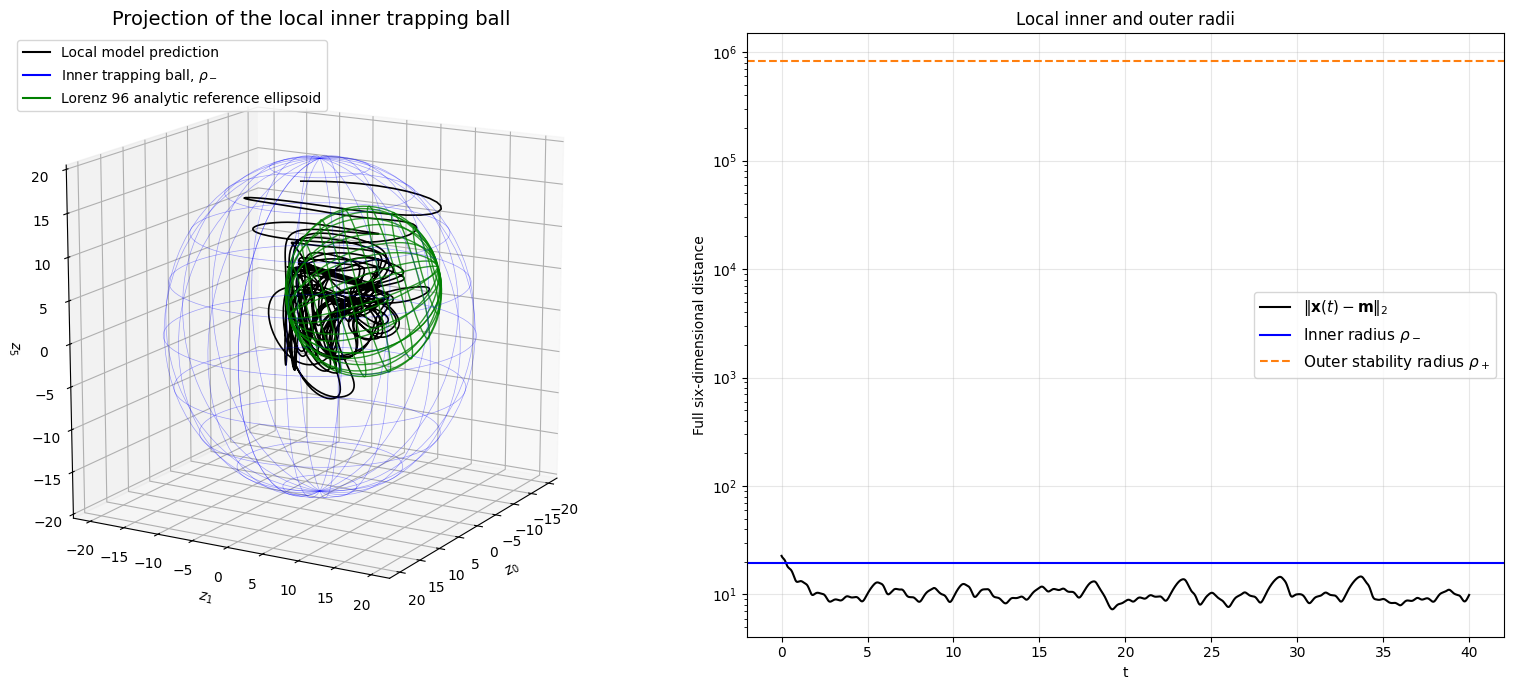

In [18]:
local_analytic_geometry = energy_geometry(C_true, L_true, Q_true, local_shift)
assert np.all(
    np.linalg.norm(local_x_test_pred - local_shift, axis=1)
    < local_clean_diagnostics["outer_radius"]
)
plot_local_trapping_region(t, local_x_test_pred, local_clean_diagnostics, local_analytic_geometry)
plt.show()

# Local trajectories starting outside the inner trapping ball

We reuse the four directions and the simulation interval of the global check.
Initial distances are twice the local inner radius, and we explicitly verify
that every initial condition lies inside the outer stability radius. The full
six-dimensional distances, shifted energies, entry times, and subsequent
containment are checked in the same way as before. The energy-growth check is
restricted to the certified annulus between the two local radii.

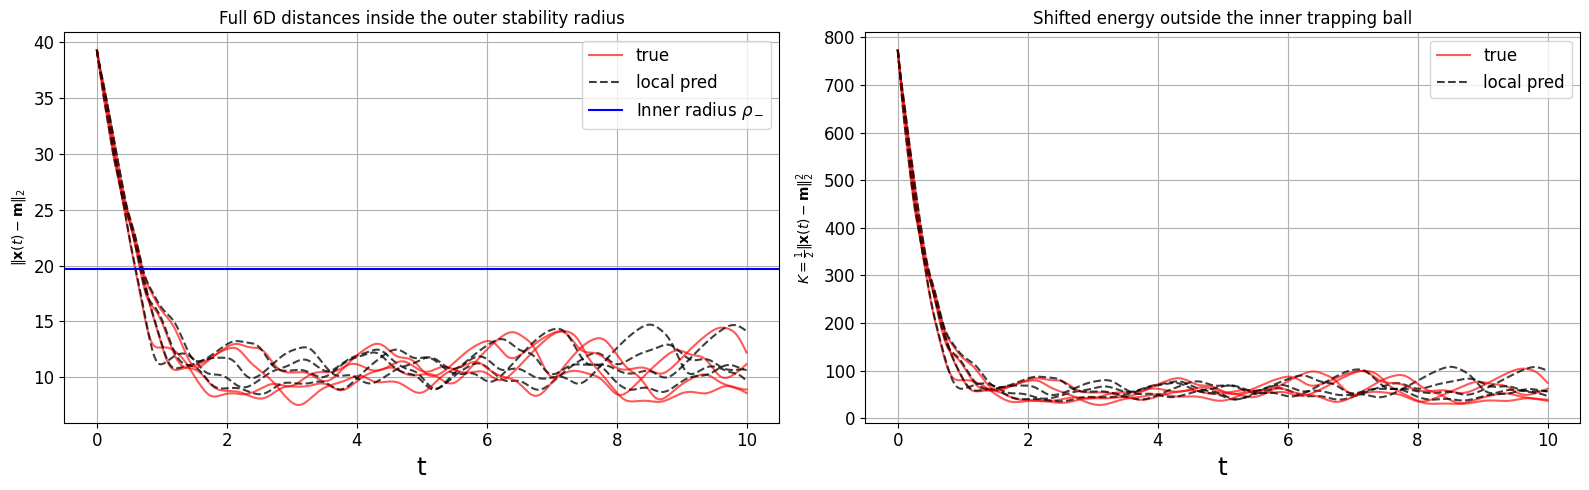

Initial distances / rho_minus = [2. 2. 2. 2.]
Entry times = [0.6, 0.7, 0.68, 0.71]
Remain inside after entry = [True, True, True, True]
Maximum energy growth in the certified annulus = -406.8970041650971


In [19]:
local_rho_minus = local_clean_diagnostics["radius"]
local_rho_plus = local_clean_diagnostics["outer_radius"]
local_outside_initial = local_shift + 2 * local_rho_minus * outside_directions
assert np.all(np.linalg.norm(local_outside_initial - local_shift, axis=1) < local_rho_plus)
local_outside_pred = np.array([
    simulate_polynomial_trajectory(local_clean_diagnostics, initial, t_outside)
    for initial in local_outside_initial
])
local_outside_true = []
for initial in local_outside_initial:
    solution = solve_ivp(
        lorenz96, (t_outside[0], t_outside[-1]), initial,
        t_eval=t_outside, args=(F,), **integrator_keywords,
    )
    assert solution.success
    local_outside_true.append(solution.y.T)
local_outside_true = np.asarray(local_outside_true)
local_radii_pred = np.linalg.norm(local_outside_pred - local_shift, axis=2)
local_radii_true = np.linalg.norm(local_outside_true - local_shift, axis=2)
local_velocity = np.array([local_model.predict(trajectory) for trajectory in local_outside_pred])
local_energy_rate = np.sum((local_outside_pred - local_shift) * local_velocity, axis=2)
local_annulus = (
    (local_radii_pred > local_rho_minus * (1 + 1e-8))
    & (local_radii_pred < local_rho_plus * (1 - 1e-8))
)
local_entry_times, local_stayed_inside = [], []
for distance in local_radii_pred:
    entered = np.flatnonzero(distance <= local_rho_minus)
    local_entry_times.append(float(t_outside[entered[0]]) if entered.size else np.nan)
    local_stayed_inside.append(
        bool(entered.size and np.all(distance[entered[0]:] <= local_rho_minus * (1 + 1e-8)))
    )

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for i in range(n_outside):
    axes[0].plot(t_outside, local_radii_true[i], "r", alpha=0.65,
                 label="true" if i == 0 else None)
    axes[0].plot(t_outside, local_radii_pred[i], "k--", alpha=0.75,
                 label="local pred" if i == 0 else None)
    axes[1].plot(t_outside, 0.5 * local_radii_true[i] ** 2, "r", alpha=0.65,
                 label="true" if i == 0 else None)
    axes[1].plot(t_outside, 0.5 * local_radii_pred[i] ** 2, "k--", alpha=0.75,
                 label="local pred" if i == 0 else None)
axes[0].axhline(local_rho_minus, color="b", label=r"Inner radius $\rho_-$")
axes[0].set(ylabel=r"$\|\mathbf{x}(t)-\mathbf{m}\|_2$",
            title="Full 6D distances inside the outer stability radius")
axes[1].set(ylabel=r"$K=\frac{1}{2}\|\mathbf{x}(t)-\mathbf{m}\|_2^2$",
            title="Shifted energy outside the inner trapping ball")
for ax in axes:
    ax.set_xlabel("t", fontsize=18)
    ax.grid(True)
    ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
fig.tight_layout()
plt.show()
print("Initial distances / rho_minus =", local_radii_pred[:, 0] / local_rho_minus)
print("Entry times =", np.round(local_entry_times, 2).tolist())
print("Remain inside after entry =", local_stayed_inside)
print("Maximum energy growth in the certified annulus =", np.max(local_energy_rate[local_annulus]))
assert np.all(np.isfinite(local_entry_times)) and all(local_stayed_inside)
assert np.all(local_radii_pred < local_rho_plus)
assert np.max(local_energy_rate[local_annulus]) < 0

# Regularized local identification from clean and noisy observations

We compare the selected local models on the same clean, 1%, and 5% observations.
Each condition uses its training-validation-selected regularizer and weight;
the physical local settings remain fixed. The STLSQ models, their annealing
results, and their accuracy metrics are reused unchanged. The stability-radius
metric for every local certificate, including the STLSQ baselines, is the outer
radius $\rho_+$, shown on a logarithmic scale. The inner trapping radius
$\rho_-$ is retained only for the geometric and trajectory-entry diagnostics;
it is not the reported local stability-radius metric.
The unregularized local metrics remain available in
`local_unregularized_reference`, with their sparsity counts shown above.

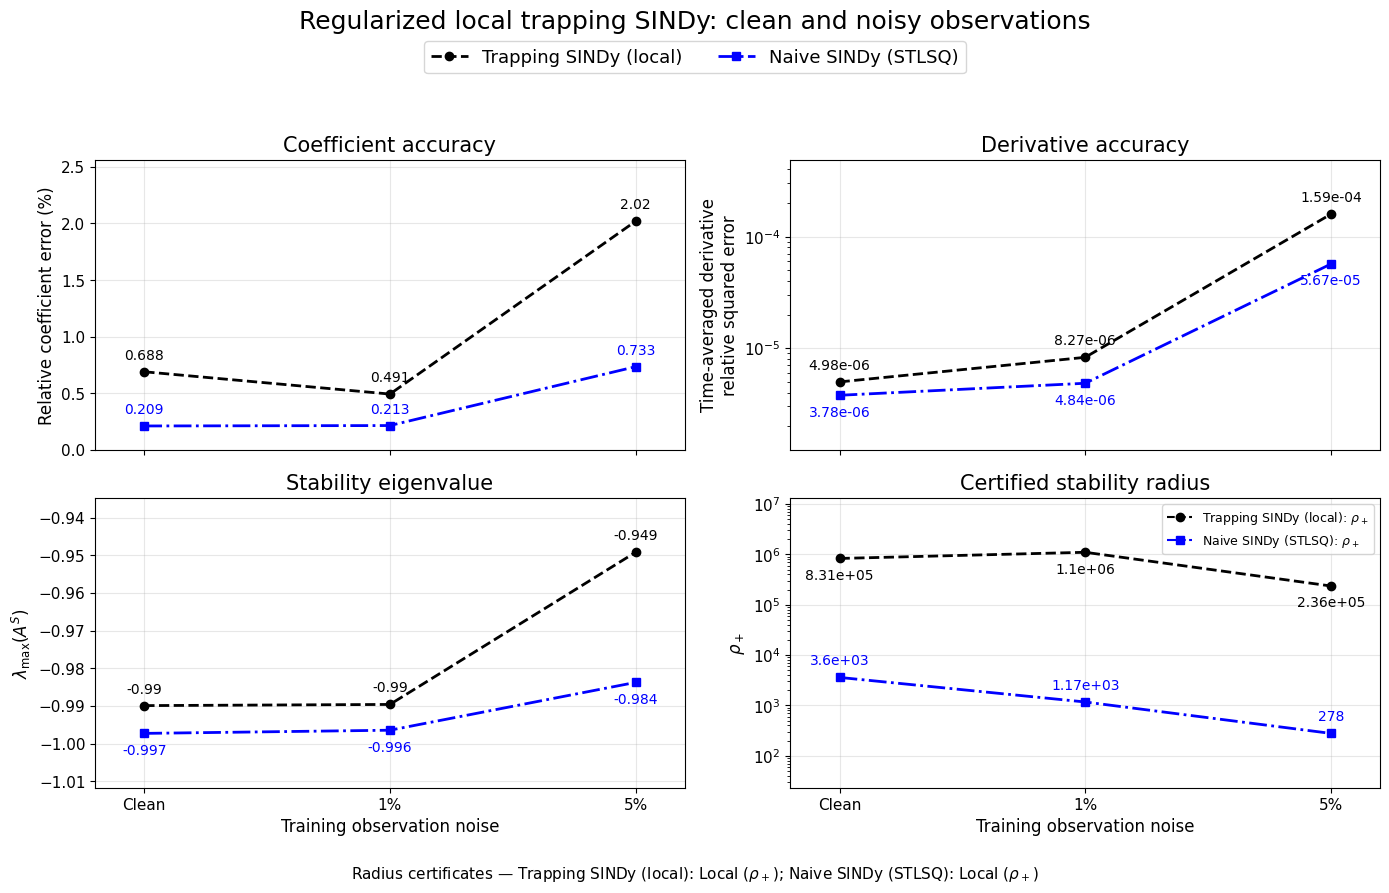

In [20]:
local_method_name = "Trapping SINDy (local)"
local_comparison_models = {}
local_comparison_diagnostics = {}
local_comparison_records = []
for noise_label, observations in noise_inputs.items():
    local_fitted_model = local_selected_models[noise_label]
    local_warnings = []
    local_fitted_Xi, local_fitted_C, local_fitted_L, local_fitted_Q = comparison_operators(local_fitted_model)
    local_diagnostics = local_stability_diagnostics(
        local_fitted_C, local_fitted_L, local_fitted_Q,
        local_fitted_model.optimizer.m_history_[-1],
    )
    local_comparison_models[(noise_label, local_method_name)] = local_fitted_model
    local_comparison_diagnostics[(noise_label, local_method_name)] = local_diagnostics
    local_derivative_pred = local_fitted_model.predict(x_test)[derivative_valid]
    local_comparison_records.append({
        "Data": noise_label, "Model": local_method_name,
        "Coefficient error": np.linalg.norm(local_fitted_Xi - Xi_lorenz96) / np.linalg.norm(Xi_lorenz96),
        "Derivative error": np.mean(
            np.sum((test_derivative_ref - local_derivative_pred) ** 2, axis=1)
            / derivative_ref_squared
        ),
        "Max eigenvalue": local_diagnostics["max_eigenvalue"],
        "Stability radius": local_diagnostics["outer_radius"],
        "Certificate": local_diagnostics["certificate"],
    })
    baseline_key = (noise_label, "Naive SINDy (STLSQ)")
    local_comparison_models[baseline_key] = comparison_models[baseline_key]
    local_comparison_diagnostics[baseline_key] = comparison_diagnostics[baseline_key]
    local_comparison_records.append(comparison_table[
        (comparison_table["Data"] == noise_label)
        & (comparison_table["Model"] == baseline_key[1])
    ].iloc[0].to_dict())
    for warning in local_warnings:
        print(noise_label, "local fit warning:", warning.message)

local_comparison_table = pd.DataFrame(local_comparison_records)
pd.testing.assert_frame_equal(
    local_comparison_table[local_comparison_table["Model"] == "Naive SINDy (STLSQ)"].reset_index(drop=True),
    comparison_table[comparison_table["Model"] == "Naive SINDy (STLSQ)"].reset_index(drop=True),
)
np.testing.assert_allclose(local_comparison_table.iloc[0]["Coefficient error"], local_coef_error)
np.testing.assert_allclose(local_comparison_table.iloc[0]["Derivative error"], local_derivative_error)
plot_noise_comparison(
    local_comparison_table, trapping_label=local_method_name,
    title="Regularized local trapping SINDy: clean and noisy observations",
)
plt.show()

# Regularized local prediction with 5% noise

We finish with the selected regularized local model fitted to the same 5% noisy observations, using
the same held-out initial condition and the same ten-Lyapunov-time interval as
the global prediction figure. The clean reference and STLSQ prediction are reused
unchanged. The local prediction is shown in black dashed lines, alongside the
red reference and blue dash-dot baseline, for all six state variables.

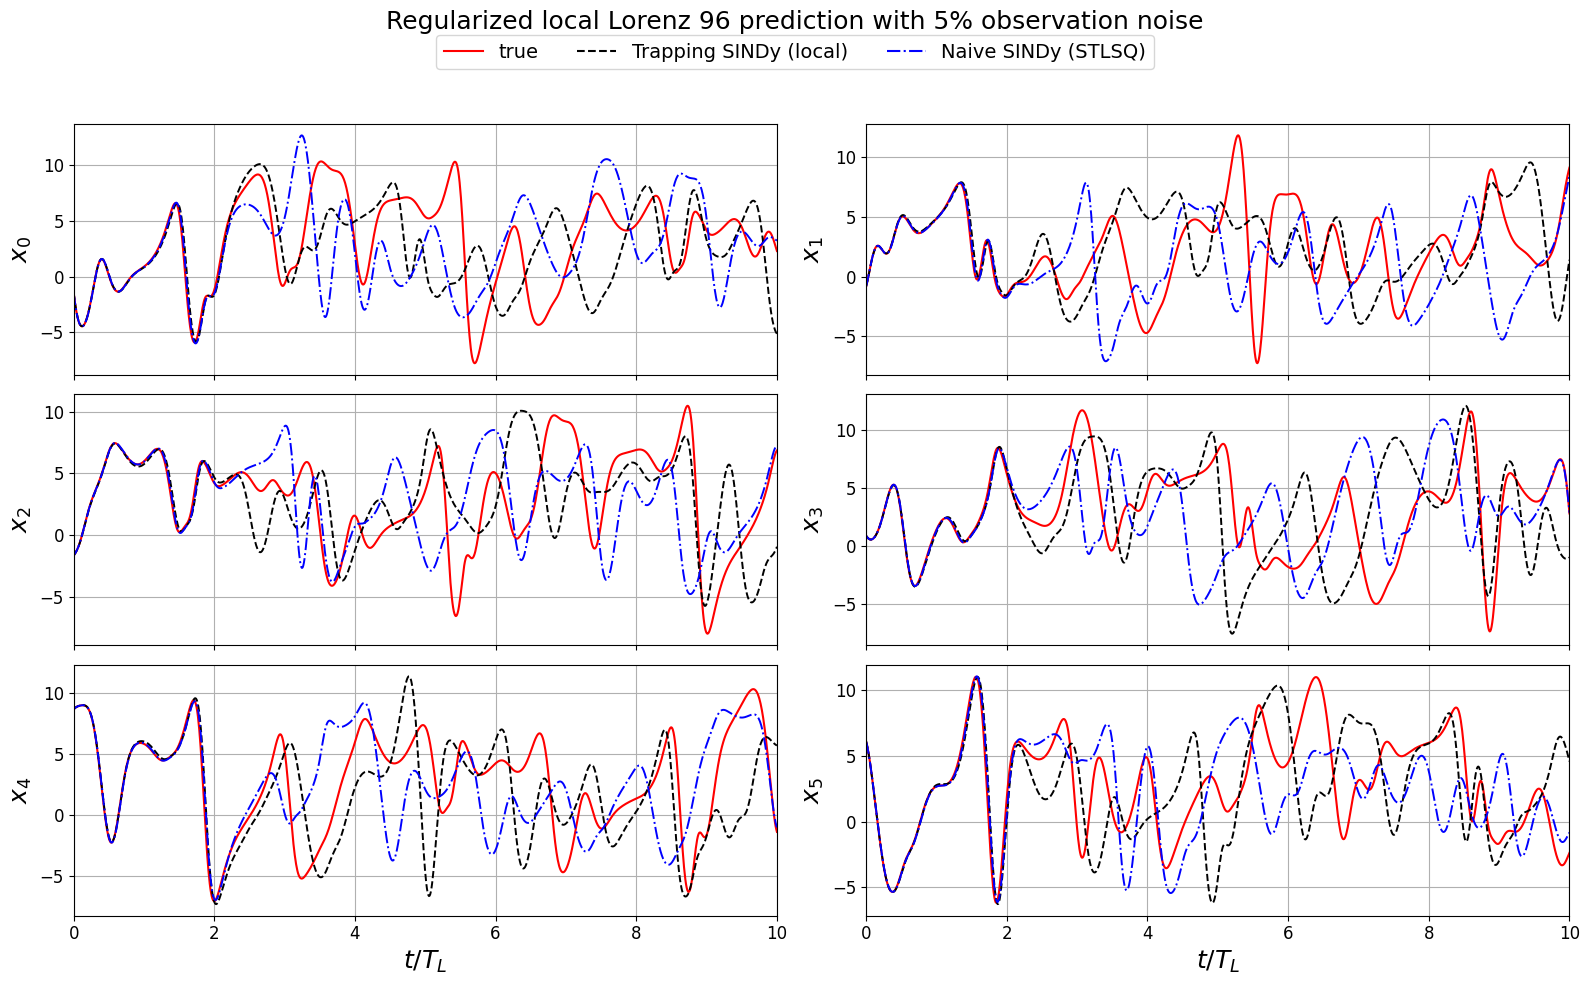

In [21]:
local_forecast_diagnostics = local_comparison_diagnostics[("5%", local_method_name)]
local_forecast_solution = solve_ivp(
    identified_rhs, (0, prediction_horizon), forecast_initial_state,
    t_eval=t_forecast,
    args=tuple(local_forecast_diagnostics[name] for name in ("C", "L", "Q")),
    **forecast_solver_options,
)
assert local_forecast_solution.success
assert np.all(np.linalg.norm(local_forecast_solution.y.T - local_forecast_diagnostics["m"], axis=1)
              < local_forecast_diagnostics["outer_radius"])
local_baseline_forecast = forecast_solutions["Naive SINDy (STLSQ)"]
assert local_comparison_models[("5%", "Naive SINDy (STLSQ)")] is comparison_models[("5%", "Naive SINDy (STLSQ)")]
np.testing.assert_allclose(local_forecast_solution.t, t_forecast)
fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(t_forecast / lyapunov_time, forecast_true_solution.y[i], "r", linewidth=1.5)
    ax.plot(local_forecast_solution.t / lyapunov_time, local_forecast_solution.y[i], "k--", linewidth=1.4)
    ax.plot(local_baseline_forecast.t / lyapunov_time, local_baseline_forecast.y[i], "b-.", linewidth=1.4)
    ax.set_ylabel(rf"$x_{i}$", fontsize=18)
    ax.set_xlim(0, prediction_lyapunov_times)
    ax.grid(True)
    ax.tick_params(labelsize=12)
for ax in axes[-1]:
    ax.set_xlabel(r"$t/T_L$", fontsize=18)
fig.legend(handles=[
    Line2D([], [], color="r", label="true"),
    Line2D([], [], color="k", linestyle="--", label=local_method_name),
    Line2D([], [], color="b", linestyle="-.", label="Naive SINDy (STLSQ)"),
], loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=3, fontsize=14)
fig.suptitle("Regularized local Lorenz 96 prediction with 5% observation noise", fontsize=18)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()